# E14-H75 - centering attribution transfer to a second fixture

**Author**: Konrad Jelen (kj)<br>
**Date**: 2026-10-09<br>
**Pipeline stage**: experiment, measurement only - the E12-H64 decomposition of the shipped `all_but_the_top(k=1)` pre-pass, repeated on a fixture that shares no document with the ibm set

**Purpose**. E12-H64 measured on the 11-summary ibm fixture that mean-centering plus re-L2-normalisation
carries 103.7% of the margin gain of the shipped `all_but_the_top(k=1)` (`src/docdistance/distance.py:94-115`)
and that removing the top principal component carries -4.5%. That reading rests on one article and one
anchor. Acceptance criterion ACC-GEOM-21 lets the finding ship only after a second fixture reproduces it.
This notebook repeats the decomposition on the three Wergeland article sections and their back-translation
paraphrases (76 statements, no ibm document) with the three-arm code of E12-H64 unchanged.

**Geometries** (estimation pool = the 76 pooled statements)

- **naive** - raw embeddings, no pre-pass
- **a - center + renorm** - subtract the pooled mean, re-L2-normalise; no SVD
- **b - project only (mean restored)** - center, remove PC1 of the centered matrix, add the pooled mean back, re-L2-normalise; the projection isolate
- **c - full shipped composition** - `all_but_the_top(k=1)` as shipped

**Panel**. Each of the three sections is an anchor. Its positive is its own back-translation paraphrase and
its negatives are the other two sections and their paraphrases: 3 positives and 12 negatives.

$$c(d) = \max\left(0,\ 1 - \frac{d}{\sqrt{2}}\right), \qquad \text{margin} = 100 \cdot \left( \min_{\text{positives}} c - \max_{\text{negatives}} c \right)$$

$$\text{recovery}(\text{arm}) = \frac{\text{margin}_{\text{arm}} - \text{margin}_{\text{naive}}}{\text{margin}_{c} - \text{margin}_{\text{naive}}}$$

`V` counts, per anchor, the negatives whose distance is at or below the distance of that anchor's positive.
The three anchors give 12 orderings; `0/12` is clean.

**Approach**
1. **Kill-gate** - pooled mean norm of the re-encoded second fixture (kill below 0.15) and the full-composition margin gain over naive (kill below +1.0 closeness point)
2. **Harness sanity check** - the E12-H64 ibm margins on OpenVINO INT8 within 5%: naive +4.71, arm a +19.95, full composition +19.41, `V` 0/24
3. **Registered experiment** - the four geometries on the second-fixture panel: `V`, margin, `d'`, recovery
4. **Readings without a bar** - `cos(uncentered PC1, mean direction)`, closeness saturation, and the conditioned-path closeness of the three ibm grounded triples with the pre-pass replaced by arm a
5. **Guardrails** - `V`, raw embeddings byte-identical, default-path `smd` and `order_gap` bit-identical, unit norms and the cost identity, `src/` and `tests/` untouched
6. **Prediction check and acceptance bar** - attribution reproduces iff arm a alone reaches 60% of the full-composition gain at `V` 0/12 and arm b stays below 30%

**Output**: `reports/E14-H75-centering-attribution-transfer-metrics.json`

## Environment

CPU only: the campaign primer keeps stage A on CPU, so CUDA is masked before any import. `CI=true` switches
the OpenVINO usage telemetry off, and the models resolve offline through the repo's `docdistance.json`.

In [1]:
import os
import logging
import warnings

os.environ["CUDA_VISIBLE_DEVICES"] = ""       # CPU only: no GPU is used in stage A
os.environ["CI"] = "true"                     # OpenVINO usage telemetry off (DEF-DEPS-11)
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"

warnings.filterwarnings("ignore")
for _n in ("torch", "transformers", "huggingface_hub", "openvino", "wtpsplit"):
    logging.getLogger(_n).setLevel(logging.ERROR)

print("device: CPU (CUDA masked)")

device: CPU (CUDA masked)


## Imports

All imports in one cell. The shipped `docdistance` functions are imported and never edited: every arm is
built inside this notebook. Autoreload is left off, because a measurement run must score one fixed copy of
the shipped code from the first cell to the last.

In [2]:
# Standard library
import gzip                        # reads the captured 1.1.5 default-path baseline
import itertools                   # the 55 ibm document pairs
import json                        # fixture, baseline and metrics files
import struct                      # float64 → its 8 bytes, for byte-level comparison
import subprocess                  # git status for the source-tree guardrail
from pathlib import Path

# Numerics
import numpy as np                 # arms, SVD, panel statistics
import ot                          # POT, the transport solver behind smd

# Plotting
import matplotlib.pyplot as plt    # inline figures, object-oriented API

# Output
from rich.console import Console, Group   # one rendered block per result
from rich.panel import Panel
from rich.progress import track           # progress bar on the encode loops
from rich.table import Table

# Shipped code under measurement
import docdistance
from docdistance.distance import (
    all_but_the_top,               # arm c, the shipped pre-pass
    closeness,                     # 1 - d / sqrt(2), clipped at 0
    compute_distance,              # default-path smd
    compute_source_conditioned,    # conditioned path
    compute_structural,            # default-path order_gap
    cost_matrix,                   # ground cost sqrt(2 - 2cos)
    smd,                           # exact Statement Mover's Distance
)
from docdistance.pipeline import DocDistance   # shipped reader, SaT segmenter and OpenVINO INT8 encoder

console = Console()
print(f"docdistance {docdistance.__version__} | POT {ot.__version__} | numpy {np.__version__}\n"
      f"package: {Path(docdistance.__file__).parent}")

docdistance 1.1.5 | POT 0.9.6.post1 | numpy 2.4.6
package: /home/lab/workspace/learning/projects/docdistance/src/docdistance


## Reproducibility

One fixed seed. No step samples: OpenVINO INT8 inference on CPU, an exact network-simplex transport solve
and a numpy SVD are deterministic, so a re-execution reproduces every reading.

In [3]:
SEED = 42
np.random.seed(SEED)
print(f"SEED={SEED}")

SEED=42


## Configuration

Fixture paths, the two document registries, the registered kill-gate, sanity, bar and prediction numbers,
and the guardrail tolerances. Everything a later cell compares against is declared here, before any
measurement.

- The record registers `1e-6` for the cost identity `cost = sqrt(2 - 2cos)` and does not name the
  arithmetic. This notebook reads it the way E12-H64 read it: in float64, on copies re-normalised to exact
  unit length. The reading on the float32 arrays as stored is printed in the same table for every geometry,
  the shipped naive one included
- The E12-H64 full-precision rows are copied from the key-numbers output of its registered run. Its metrics
  file is not read at run time, because another process rewrote the E12-H64 notebook and its metrics file on
  this machine while this notebook was being built (2026-10-09 11:09)

In [4]:
ROOT = Path("/home/lab/workspace/learning/projects/docdistance")                 # repo root
STATEMENTS_PATH = ROOT / "data/processed/structure-fixture/statements.json"        # second fixture, pre-segmented
IBM_DIR = ROOT / "data/interim/exec-summaries/ibm-ai-adoption"                    # sanity fixture: summaries, source
BASELINE_PATH = ROOT / "reports/E13-campaign/baseline/default-path.json.gz"       # 1.1.5 readings captured at bd0002e
METRICS_PATH = ROOT / "reports/E14-H75-centering-attribution-transfer-metrics.json"

# second fixture: the three Wergeland sections and their back-translation paraphrases
WERG_BASES = ["werg-a", "werg-b", "werg-c"]                     # the three anchors
WERG_KEYS = WERG_BASES + [f"{b}~bt" for b in WERG_BASES]         # estimation pool = scored documents
WERG_EXPECTED_N = {"werg-a": 11, "werg-b": 13, "werg-c": 14}    # registered statement counts
WERG_POOL_N = 76                                                # registered pool size
WERG_PAIRS = [(a, f"{a}~bt") for a in WERG_BASES] + [           # 3 positives, then 12 negatives
    (a, k) for a in WERG_BASES for o in WERG_BASES if o != a for k in (o, f"{o}~bt")]

# ibm panel of E12-H64 (file, label, tier); the order is kept because the pooled matrix is built in it
IBM_DOCS = [
    ("exec-summary-gold-opus-4-6.md",     "gold",   "gold"),    # anchor
    ("exec-summary-gold-2-opus-4-6.md",   "gold-2", "gold"),
    ("exec-summary-1-opus-4-6.md",        "v1",     "gold"),
    ("exec-summary-2-opus-4-6.md",        "v2",     "gold"),
    ("exec-summary-opus-4-6.md",          "opus",   "gold"),
    ("exec-summary-sonnet-4-6.md",        "sonnet", "gold"),
    ("exec-summary-haiku-4-5.md",         "haiku",  "gold"),
    ("exec-summary-adv1-a-sonnet-4-6.md", "adv1-a", "adv1"),
    ("exec-summary-adv1-b-sonnet-4-6.md", "adv1-b", "adv1"),
    ("exec-summary-adv2-a-haiku-4-5.md",  "adv2-a", "adv2"),
    ("exec-summary-adv2-b-haiku-4-5.md",  "adv2-b", "adv2"),
]
IBM_REFERENCE = "gold"
IBM_LABELS = [l for _, l, _ in IBM_DOCS]
IBM_TIER = {l: t for _, l, t in IBM_DOCS}
IBM_STEM = {l: f.removeprefix("exec-summary-").removesuffix(".md") for f, l, _ in IBM_DOCS}   # baseline.py keys
IBM_GOLD = [l for l in IBM_LABELS if IBM_TIER[l] == "gold" and l != IBM_REFERENCE]
IBM_ADV = [l for l in IBM_LABELS if IBM_TIER[l] != "gold"]
IBM_NONREF = [l for l in IBM_LABELS if l != IBM_REFERENCE]
GROUNDED = [("gold", "v1"), ("gold", "adv1-a"), ("gold", "adv2-b")]   # the three triples of baseline.py

# geometry names: the E12-H64 arm names; its "baseline" row is the "naive" row of the E14-H75 record
NAIVE, ARM_A, ARM_B, ARM_C = "naive", "a center+renorm", "b project-only", "c full shipped"
GEOMS = [NAIVE, ARM_A, ARM_B, ARM_C]
K = 1                               # the shipped setting, all_but_the_top(k=1)
SMD_MAX = float(np.sqrt(2.0))       # closeness() clips to 0 at or above this distance

# kill-gate (registered)
GATE_MIN_MEAN_NORM = 0.15           # pooled mean norm below this: centering cannot be the cause
GATE_MIN_FULL_GAIN_PTS = 1.0        # full-composition margin gain below this: no gain to attribute

# harness sanity check (registered): E12-H64 ibm margins on OpenVINO INT8, each within 5%, V 0/24
SANITY_REGISTERED = {NAIVE: 4.71, ARM_A: 19.95, ARM_C: 19.41}
SANITY_RTOL = 0.05
H64_FULL_PRECISION = {              # E12-H64 key-numbers output, registered run of 2026-09-01 (informational)
    NAIVE: 4.708317407970153, ARM_A: 19.952554955749292, ARM_B: 4.044454232474026, ARM_C: 19.414396463424623}
H64_STATEMENTS = 98                 # E12-H64 pooled ibm statement count

# acceptance bar (registered)
BAR_RECOVERY = 0.60                 # the attributed arm reaches at least this share of the full-composition gain
BAR_B_MAX = 0.30                    # arm b stays below this share

# prediction (registered)
PRED_MIN_MEAN_NORM = 0.9            # pooled mean norm above this
PRED_MIN_COS = 0.999                # cos(uncentered PC1, mean direction) at least this
PRED_MIN_A_RECOVERY = 0.90          # arm a recovery at least this
PRED_B_BAND = (-0.15, 0.15)         # arm b recovery inside this band

# guardrail tolerances
NORM_TOL = 1e-6                     # registered: unit norms to 1e-6
COST_ID_TOL = 1e-6                  # registered: cost = sqrt(2 - 2cos) to 1e-6 (float64, exact-unit copies)
TRI_TOL = 1e-9                      # triangle-inequality slack over every statement triple

# semantic colours, one palette for the rich output and every figure
C_POS, C_NEG = "#2ECC71", "#E74C3C"             # same-content pair / different-content pair, bar met / bar missed
C_VARIANT, C_REFERENCE = "#3498DB", "#7F8C8D"   # measured variant / unmodified reference

NOT_RUN = "[yellow]not run - the kill-gate fired or the harness sanity check failed[/yellow]"
METRICS = {"id": "E14-H75", "slug": "centering-attribution-transfer"}   # every section adds its block
KEY = {}                                                                 # key numbers for the campaign result JSON

cfg = Table(title="E14-H75 configuration", header_style="bold cyan")
cfg.add_column("group"); cfg.add_column("key"); cfg.add_column("value", style="bold")
for group, key, value in [
    ("fixture", "second fixture", f"{', '.join(WERG_KEYS)} of {STATEMENTS_PATH.relative_to(ROOT)}"),
    ("fixture", "panel", f"{len(WERG_BASES)} anchors, {len(WERG_BASES)} positives, {len(WERG_PAIRS) - len(WERG_BASES)} negatives"),
    ("fixture", "estimation pool", f"{WERG_POOL_N} pooled statements, no ibm document"),
    ("fixture", "sanity fixture", f"ibm panel, {len(IBM_DOCS)} summaries, anchor {IBM_REFERENCE}, {len(IBM_GOLD)} x {len(IBM_ADV)} orderings"),
    ("models", "encoder", "mmBERT OpenVINO INT8 (CPU), the shipped default"),
    ("models", "arms", f"{ARM_A} | {ARM_B} | {ARM_C} (k={K})"),
    ("kill-gate", "pooled mean norm", f"kill below {GATE_MIN_MEAN_NORM}"),
    ("kill-gate", "full-composition margin gain", f"kill below {GATE_MIN_FULL_GAIN_PTS:+.1f} closeness point"),
    ("sanity", "ibm margins", " | ".join(f"{n} {v:+.2f}" for n, v in SANITY_REGISTERED.items()) + f", each within {SANITY_RTOL:.0%}, V 0/24"),
    ("bar", "attribution reproduces", f"arm a alone at or above {BAR_RECOVERY:.0%} of the full gain at V 0/12, arm b below {BAR_B_MAX:.0%}"),
    ("prediction", "clauses", f"mean norm > {PRED_MIN_MEAN_NORM} | cos >= {PRED_MIN_COS} | arm a >= {PRED_MIN_A_RECOVERY:.0%} | "
                              f"arm b in {PRED_B_BAND[0]:+.0%} .. {PRED_B_BAND[1]:+.0%} | V 0/12 in arms a and c"),
    ("guardrails", "tolerances", f"unit norm {NORM_TOL:.0e} | cost identity {COST_ID_TOL:.0e} | triangle slack {TRI_TOL:.0e}"),
    ("output", "metrics json", str(METRICS_PATH.relative_to(ROOT))),
]:
    cfg.add_row(group, key, value)
console.print(cfg)

                                               E14-H75 configuration                                               
┏━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ group      ┃ key                          ┃ value                                                               ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ fixture    │ second fixture               │ werg-a, werg-b, werg-c, werg-a~bt, werg-b~bt, werg-c~bt of          │
│            │                              │ data/processed/structure-fixture/statements.json                    │
│ fixture    │ panel                        │ 3 anchors, 3 positives, 12 negatives                                │
│ fixture    │ estimation pool              │ 76 pooled statements, no ibm document                               │
│ fixture    │ sanity fixture               │ ibm panel, 11 summaries, anchor gold, 6 x 4 orderings               │
│ models     │ encoder                      │ mmBERT OpenVINO INT8 (CPU), the shipped default                     │
│ models     │ arms                         │ a center+renorm | b project-only | c full shipped (k=1)             │
│ kill-gate  │ pooled mean norm             │ kill below 0.15                                                     │
│ kill-gate  │ full-composition margin gain │ kill below +1.0 closeness point                                     │
│ sanity     │ ibm margins                  │ naive +4.71 | a center+renorm +19.95 | c full shipped +19.41, each  │
│            │                              │ within 5%, V 0/24                                                   │
│ bar        │ attribution reproduces       │ arm a alone at or above 60% of the full gain at V 0/12, arm b below │
│            │                              │ 30%                                                                 │
│ prediction │ clauses                      │ mean norm > 0.9 | cos >= 0.999 | arm a >= 90% | arm b in -15% ..    │
│            │                              │ +15% | V 0/12 in arms a and c                                       │
│ guardrails │ tolerances                   │ unit norm 1e-06 | cost identity 1e-06 | triangle slack 1e-09        │
│ output     │ metrics json                 │ reports/E14-H75-centering-attribution-transfer-metrics.json         │
└────────────┴──────────────────────────────┴─────────────────────────────────────────────────────────────────────┘

## Second fixture - load and encode

The six Wergeland documents are read as stored statement lists and encoded with the shipped OpenVINO INT8
encoder, one encode call per document as the pipeline does. The membership checks run first: every pooled
document belongs to the Wergeland article, the counts match the record (11, 13, 14 and 76 pooled), and each
paraphrase aligns statement for statement with its base.

In [5]:
all_statements = json.loads(STATEMENTS_PATH.read_text(encoding="utf-8"))
werg = {k: all_statements[k] for k in WERG_KEYS}

ARTICLES_IN_POOL = sorted({werg[k]["article"] for k in WERG_KEYS})
COUNTS_OK = all(len(werg[b]["statements"]) == n and len(werg[f"{b}~bt"]["statements"]) == n
                for b, n in WERG_EXPECTED_N.items())
ALIGN_OK = all(werg[f"{b}~bt"]["paraphrase_of"] == b and werg[f"{b}~bt"]["block_id"] == werg[b]["block_id"]
               for b in WERG_BASES)
N_POOL_W = sum(len(werg[k]["statements"]) for k in WERG_KEYS)
FIXTURE_OK = ARTICLES_IN_POOL == ["wergeland"] and COUNTS_OK and ALIGN_OK and N_POOL_W == WERG_POOL_N

tbl = Table(title=f"second fixture - {N_POOL_W} statements over {len(WERG_KEYS)} documents", header_style="bold cyan")
for col, just in [("document", "left"), ("article", "left"), ("kind", "left"), ("statements", "right"), ("first statement", "left")]:
    tbl.add_column(col, justify=just)
for k in WERG_KEYS:
    tbl.add_row(k, werg[k]["article"], werg[k]["kind"], str(len(werg[k]["statements"])), werg[k]["statements"][0][:70])
console.print(Group(tbl, Panel(
    f"articles in the pool: {', '.join(ARTICLES_IN_POOL)} (ibm documents in the pool: "
    f"{sum(werg[k]['article'] == 'ibm' for k in WERG_KEYS)})\n"
    f"counts match the record: {COUNTS_OK} | paraphrases align with their base (paraphrase_of, block ids): {ALIGN_OK} | "
    f"pooled statements: {N_POOL_W}",
    title="membership checks", border_style="green" if FIXTURE_OK else "red")))
assert FIXTURE_OK, "second fixture does not match the registered record"

                                  second fixture - 76 statements over 6 documents                                  
┏━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ document  ┃ article   ┃ kind       ┃ statements ┃ first statement                                               ┃
┡━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ werg-a    │ wergeland │ summary    │         11 │ Artificial intelligence, or AI, is steadily growing in use in │
│           │           │            │            │ many are                                                      │
│ werg-b    │ wergeland │ summary    │         13 │ While praising the benefits of AI-based tools, it is          │
│           │           │            │            │ important to be a                                             │
│ werg-c    │ wergeland │ summary    │         14 │ As we have seen, AI can bring a lot of benefits to solving    │
│           │           │            │            │ problems, i                                                   │
│ werg-a~bt │ wergeland │ paraphrase │         11 │ Artificial intelligence, or AI, is constantly being used in   │
│           │           │            │            │ many areas                                                    │
│ werg-b~bt │ wergeland │ paraphrase │         13 │ While the benefits of AI-based tools are praised, it is       │
│           │           │            │            │ important to b                                                │
│ werg-c~bt │ wergeland │ paraphrase │         14 │ As we have seen, AI can bring many benefits in solving        │
│           │           │            │            │ problems that i                                               │
└───────────┴───────────┴────────────┴────────────┴───────────────────────────────────────────────────────────────┘
╭─────────────────────────────────────────────── membership checks ───────────────────────────────────────────────╮
│ articles in the pool: wergeland (ibm documents in the pool: 0)                                                  │
│ counts match the record: True | paraphrases align with their base (paraphrase_of, block ids): True | pooled     │
│ statements: 76                                                                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [6]:
dd = DocDistance()        # backend openvino, offline: the shipped default pipeline
encoder = dd.encoder      # first access loads the SaT segmenter and the OpenVINO INT8 mmBERT encoder
print(f"encoder: {type(encoder).__name__} | segmenter: {type(dd.segmenter).__name__}")

encoder: OpenVINOEncoder | segmenter: Segmenter


In [7]:
emb_w = {}
for key in track(WERG_KEYS, description="encode the second fixture", console=console):
    emb_w[key] = encoder.encode(werg[key]["statements"])

## Arms, panels and readings

Definitions only, no measurement. `three_arms` is the three-arm block of E12-H64 with its expressions
unchanged and the fixture passed in as an argument. `ibm_panel` is the E12-H64 panel. `werg_panel` is the
registered second-fixture panel. The last cell of the section snapshots the raw embeddings and the shipped
default-path readings of the second fixture before any arm runs.

In [8]:
def l2(M: np.ndarray) -> np.ndarray:
    """Re-L2-normalise the rows (the E12-H64 helper)."""
    return M / (np.linalg.norm(M, axis=1, keepdims=True) + 1e-9)


def repack(fixed: np.ndarray, emb: dict) -> dict:
    """Split a transformed pooled matrix back into the per-document embedding dict."""
    out, off = {}, 0
    for l in emb:
        n = len(emb[l])
        out[l] = fixed[off:off + n].astype(np.float32)
        off += n
    return out


def three_arms(emb: dict) -> dict:
    """E12-H64 arms a, b, c over the pooled statements of ``emb`` (expressions unchanged)."""
    POOL = np.concatenate([emb[l] for l in emb], 0)
    mean_vec = POOL.mean(0)
    centered = POOL - mean_vec
    _, _, Vt_centered = np.linalg.svd(centered, full_matrices=False)
    pc1_centered = Vt_centered[:K]
    return {
        ARM_A: repack(l2(centered), emb),
        ARM_B: repack(l2(centered - centered @ pc1_centered.T @ pc1_centered + mean_vec), emb),
        ARM_C: all_but_the_top(emb, k=K),
    }

In [9]:
def ibm_panel(eb: dict) -> dict:
    """E12-H64 panel: distance of every non-anchor summary to the anchor, V over 6 gold x 4 adversarial."""
    dist = {l: smd(eb[l], eb[IBM_REFERENCE]) for l in IBM_NONREF}
    g = np.array([dist[l] for l in IBM_GOLD])
    a = np.array([dist[l] for l in IBM_ADV])
    clos = {l: closeness(dist[l]) for l in IBM_NONREF}
    gc = np.array([clos[l] for l in IBM_GOLD])
    ac = np.array([clos[l] for l in IBM_ADV])
    pooled = float(np.sqrt((g.var() + a.var()) / 2)) or 1e-9
    return dict(
        dist=dist, clos=clos,
        V=int(sum(1 for gg in g for aa in a if gg >= aa)),
        margin_pts=float(gc.min() - ac.max()) * 100.0,
        dprime=float((a.mean() - g.mean()) / pooled),
        R=float(a.mean() / g.mean()),
        DR=float(np.concatenate([g, a]).std()),
    )


def werg_panel(eb: dict) -> dict:
    """Second-fixture panel: per anchor 1 positive (own paraphrase) and 4 negatives (the other sections)."""
    pos = {f"{a}|{a}~bt": smd(eb[a], eb[f"{a}~bt"]) for a in WERG_BASES}
    neg = {f"{a}|{k}": smd(eb[a], eb[k])
           for a in WERG_BASES for o in WERG_BASES if o != a for k in (o, f"{o}~bt")}
    p = np.array(list(pos.values()))
    n = np.array(list(neg.values()))
    v_by_anchor = {a: int(sum(1 for k, d in neg.items() if k.startswith(f"{a}|") and pos[f"{a}|{a}~bt"] >= d))
                   for a in WERG_BASES}
    min_pos_c = min(closeness(d) for d in p)
    max_neg_c = max(closeness(d) for d in n)
    pooled = float(np.sqrt((p.var() + n.var()) / 2)) or 1e-9
    return dict(
        pos=pos, neg=neg,
        V=sum(v_by_anchor.values()), V_by_anchor=v_by_anchor,
        min_pos_closeness=float(min_pos_c), max_neg_closeness=float(max_neg_c),
        margin_pts=float(min_pos_c - max_neg_c) * 100.0,
        dprime=float((n.mean() - p.mean()) / pooled),
        R=float(n.mean() / p.mean()),
        DR=float(np.concatenate([p, n]).std()),
    )

In [10]:
def hexf(x: float) -> str:
    """The 8 bytes of a float64 as hex: equal strings are bit-identical values."""
    return struct.pack("<d", x).hex()


def default_path(eb: dict, pairs: list) -> dict:
    """Shipped default-path readings (anisotropy off) per pair: (smd bytes, order_gap bytes)."""
    return {f"{a}|{b}": (hexf(compute_distance(eb[a], eb[b]).smd), hexf(compute_structural(eb[a], eb[b]).order_gap))
            for a, b in pairs}


def raw_unchanged(eb: dict, snapshot: dict) -> bool:
    """True when every embedding array still has the bytes of its snapshot."""
    return all(eb[k].tobytes() == snapshot[k] for k in snapshot)


def pool_geometry(pool: np.ndarray) -> dict:
    """Mean norm, singular spectra, and |cos| of the top singular vector with the mean direction."""
    mean = pool.mean(0)
    mean_dir = mean / np.linalg.norm(mean)
    _, sv_u, Vt_u = np.linalg.svd(pool, full_matrices=False)
    _, sv_c, Vt_c = np.linalg.svd(pool - mean, full_matrices=False)
    return dict(mean_norm=float(np.linalg.norm(mean)),
                cos_uncentered_pc1_mean=float(abs(Vt_u[0] @ mean_dir)),
                cos_centered_pc1_mean=float(abs(Vt_c[0] @ mean_dir)),
                sv_uncentered=sv_u, sv_centered=sv_c)


def metric_property(eb: dict) -> dict:
    """The three E12-H64 reads on one geometry: unit norms, cost = sqrt(2 - 2cos), triangle inequality."""
    P32 = np.concatenate(list(eb.values()), 0)
    norm_dev = float(np.abs(np.linalg.norm(P32, axis=1) - 1.0).max())
    P64 = P32.astype(np.float64)
    P64 = P64 / np.linalg.norm(P64, axis=1, keepdims=True)                 # exactly unit in float64
    C64 = cost_matrix(P64, P64)
    cost_id64 = float(np.abs(C64 - np.sqrt(np.clip(2.0 - 2.0 * (P64 @ P64.T), 0.0, None))).max())
    S32 = P32.astype(np.float64)
    cost_id32 = float(np.abs(cost_matrix(P32, P32).astype(np.float64)
                             - np.sqrt(np.clip(2.0 - 2.0 * (S32 @ S32.T), 0.0, None))).max())
    tri = float((C64[:, None, :] - C64[:, :, None] - C64[None, :, :]).max())   # every (i, j, k) triple
    return dict(max_unit_norm_dev=norm_dev, max_cost_identity_dev_float64=cost_id64,
                max_cost_identity_dev_float32=cost_id32, max_triangle_slack=tri,
                holds=bool(norm_dev <= NORM_TOL and cost_id64 <= COST_ID_TOL and tri <= TRI_TOL))

In [11]:
POOL_W = np.concatenate([emb_w[k] for k in WERG_KEYS], 0)
RAW_W_BYTES = {k: emb_w[k].tobytes() for k in WERG_KEYS}     # raw-embedding snapshot, before any arm
DEFAULT_W_BEFORE = default_path(emb_w, WERG_PAIRS)           # shipped smd and order_gap, before any arm
_k = f"{WERG_PAIRS[0][0]}|{WERG_PAIRS[0][1]}"
console.print(Panel(
    f"pooled matrix {POOL_W.shape[0]} x {POOL_W.shape[1]}, dtype {POOL_W.dtype}\n"
    f"default-path snapshot over {len(DEFAULT_W_BEFORE)} pairs, first pair {_k}: "
    f"smd 0x{DEFAULT_W_BEFORE[_k][0]}, order_gap 0x{DEFAULT_W_BEFORE[_k][1]}",
    title="second fixture encoded, snapshot taken", border_style="cyan"))

╭──────────────────────────────────── second fixture encoded, snapshot taken ─────────────────────────────────────╮
│ pooled matrix 76 x 768, dtype float32                                                                           │
│ default-path snapshot over 15 pairs, first pair werg-a|werg-a~bt: smd 0xbae8a25be4bac13f, order_gap             │
│ 0x0030cc4793bf3e3f                                                                                              │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Kill-gate

Two registered readings on the re-encoded second fixture, taken before the panel run. A pooled mean norm
below 0.15 means the statements share no common direction and centering cannot be the cause. A
full-composition margin gain below +1.0 closeness point over naive means the fixture has no gain to
attribute. Either one ends the run with `Killed-at-gate`.

In [12]:
MEAN_NORM_W = float(np.linalg.norm(POOL_W.mean(0)))
UNIT_DEV_W = float(np.abs(np.linalg.norm(POOL_W, axis=1) - 1.0).max())

naive_w = werg_panel(emb_w)
full_w = werg_panel(all_but_the_top(emb_w, k=K))            # the shipped composition
FULL_GAIN_W = full_w["margin_pts"] - naive_w["margin_pts"]

GATE_NORM_PASSED = bool(MEAN_NORM_W >= GATE_MIN_MEAN_NORM)
GATE_GAIN_PASSED = bool(FULL_GAIN_W >= GATE_MIN_FULL_GAIN_PTS)
GATE_PASSED = GATE_NORM_PASSED and GATE_GAIN_PASSED
PROCEED = GATE_PASSED
SANITY_PASSED = None        # set by the harness sanity check when it runs

METRICS["kill_gate"] = {
    "pooled_mean_norm": MEAN_NORM_W, "min_pooled_mean_norm": GATE_MIN_MEAN_NORM, "norm_reading_passed": GATE_NORM_PASSED,
    "naive_margin_pts": naive_w["margin_pts"], "full_composition_margin_pts": full_w["margin_pts"],
    "full_composition_margin_gain_pts": FULL_GAIN_W, "min_full_composition_margin_gain_pts": GATE_MIN_FULL_GAIN_PTS,
    "gain_reading_passed": GATE_GAIN_PASSED, "passed": GATE_PASSED,
    "pooled_statements": int(POOL_W.shape[0]), "max_unit_norm_dev_raw": UNIT_DEV_W,
}
KEY.update(pooled_mean_norm=MEAN_NORM_W, naive_margin_pts=naive_w["margin_pts"],
           arm_c_margin_pts=full_w["margin_pts"], full_composition_margin_gain_pts=FULL_GAIN_W,
           n_statements=int(POOL_W.shape[0]), n_documents=len(WERG_KEYS))

console.print(Panel(
    f"pooled mean norm = [bold]{MEAN_NORM_W:.4f}[/bold]   kill below {GATE_MIN_MEAN_NORM}   → "
    f"{'passed' if GATE_NORM_PASSED else 'KILLED'}\n"
    f"full-composition margin gain = [bold]{FULL_GAIN_W:+.2f}[/bold] pts "
    f"(naive {naive_w['margin_pts']:+.2f} → full composition {full_w['margin_pts']:+.2f})   "
    f"kill below {GATE_MIN_FULL_GAIN_PTS:+.1f}   → {'passed' if GATE_GAIN_PASSED else 'KILLED'}\n"
    f"V naive {naive_w['V']}/12, full composition {full_w['V']}/12 | pooled statements {POOL_W.shape[0]}, "
    f"max |‖x‖-1| = {UNIT_DEV_W:.2e}\n"
    f"gate: [bold]{'PASSED - the run proceeds' if GATE_PASSED else 'FIRED - the run ends here, verdict Killed-at-gate'}[/bold]",
    title="kill-gate", border_style="green" if GATE_PASSED else "red"))

╭─────────────────────────────────────────────────── kill-gate ───────────────────────────────────────────────────╮
│ pooled mean norm = 0.9476   kill below 0.15   → passed                                                          │
│ full-composition margin gain = +38.90 pts (naive +15.84 → full composition +54.74)   kill below +1.0   → passed │
│ V naive 0/12, full composition 0/12 | pooled statements 76, max |‖x‖-1| = 1.19e-07                              │
│ gate: PASSED - the run proceeds                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Harness sanity check

The same three-arm code scores the ibm panel of E12-H64 before the second-fixture arms are read. The
registered check: naive margin +4.71, arm a +19.95 and full composition +19.41 closeness points, each within
5%, with the standing `V` 0/24 on the three rows. The ibm summaries go through the shipped reader, SaT
segmenter and encoder (`DocDistance.embed_statements`). The shipped default-path `smd` and `order_gap` of
all 55 ibm pairs are compared byte for byte with the baseline captured at commit `bd0002e`. A failed check
ends the run with `Blocked`.

In [13]:
if PROCEED:
    ibm_statements, emb_i = {}, {}
    for fname, label, _ in track(IBM_DOCS, description="segment and encode the ibm panel", console=console):
        ibm_statements[label], emb_i[label] = dd.embed_statements(IBM_DIR / "summaries" / fname)
else:
    console.print(NOT_RUN)

In [14]:
if PROCEED:
    RAW_I_BYTES = {l: emb_i[l].tobytes() for l in IBM_LABELS}                 # raw-embedding snapshot, before any arm
    emb_stem = {IBM_STEM[l]: emb_i[l] for l in IBM_LABELS}
    IBM_PAIRS = list(itertools.combinations(sorted(emb_stem), 2))             # the 55 pairs, keyed as baseline.py keys them
    DEFAULT_I_BEFORE = default_path(emb_stem, IBM_PAIRS)                      # shipped smd and order_gap, before any arm
    with gzip.open(BASELINE_PATH, "rt", encoding="utf-8") as fh:
        baseline = json.load(fh)
    BASELINE_SMD_EQUAL_BEFORE = sum(DEFAULT_I_BEFORE[k][0] == hexf(baseline["pairs"][k]["semantic"]["smd"]) for k in DEFAULT_I_BEFORE)
    BASELINE_GAP_EQUAL_BEFORE = sum(DEFAULT_I_BEFORE[k][1] == hexf(baseline["pairs"][k]["structural"]["order_gap"]) for k in DEFAULT_I_BEFORE)

    ARMS_I = three_arms(emb_i)
    SCORE_I = {NAIVE: ibm_panel(emb_i), **{n: ibm_panel(eb) for n, eb in ARMS_I.items()}}
    FULL_GAIN_I = SCORE_I[ARM_C]["margin_pts"] - SCORE_I[NAIVE]["margin_pts"]
    RECOVERY_I = {n: (SCORE_I[n]["margin_pts"] - SCORE_I[NAIVE]["margin_pts"]) / FULL_GAIN_I for n in ARMS_I}
    N_IBM_STATEMENTS = sum(len(s) for s in ibm_statements.values())

    sanity_rows = {}
    for name, reg in SANITY_REGISTERED.items():
        obs = SCORE_I[name]["margin_pts"]
        rel = abs(obs - reg) / abs(reg)
        sanity_rows[name] = dict(registered_margin_pts=reg, observed_margin_pts=obs, rel_delta=rel,
                                 within_tolerance=bool(rel <= SANITY_RTOL), V=SCORE_I[name]["V"],
                                 abs_diff_vs_h64_full_precision=abs(obs - H64_FULL_PRECISION[name]))
    SANITY_MAX_REL = max(r["rel_delta"] for r in sanity_rows.values())
    SANITY_V_ZERO = all(r["V"] == 0 for r in sanity_rows.values())
    SANITY_PASSED = bool(all(r["within_tolerance"] for r in sanity_rows.values()) and SANITY_V_ZERO)
    PROCEED = SANITY_PASSED

    METRICS["sanity_check"] = {
        "tolerance_relative": SANITY_RTOL, "rows": sanity_rows, "max_rel_delta": SANITY_MAX_REL,
        "V_zero_on_registered_rows": SANITY_V_ZERO, "passed": SANITY_PASSED,
        "ibm_statements": N_IBM_STATEMENTS, "ibm_statements_e12_h64": H64_STATEMENTS,
        "ibm_arms": {n: {k: SCORE_I[n][k] for k in ("V", "margin_pts", "dprime", "R", "DR")} for n in GEOMS},
        "ibm_recovery": RECOVERY_I, "ibm_full_composition_margin_gain_pts": FULL_GAIN_I,
        "ibm_arm_b_abs_diff_vs_h64_full_precision": abs(SCORE_I[ARM_B]["margin_pts"] - H64_FULL_PRECISION[ARM_B]),
        "baseline_smd_equal_before_arms": f"{BASELINE_SMD_EQUAL_BEFORE}/{len(IBM_PAIRS)}",
        "baseline_order_gap_equal_before_arms": f"{BASELINE_GAP_EQUAL_BEFORE}/{len(IBM_PAIRS)}",
    }
    KEY.update(ibm_naive_margin_pts=SCORE_I[NAIVE]["margin_pts"], ibm_arm_a_margin_pts=SCORE_I[ARM_A]["margin_pts"],
               ibm_arm_b_margin_pts=SCORE_I[ARM_B]["margin_pts"], ibm_arm_c_margin_pts=SCORE_I[ARM_C]["margin_pts"],
               ibm_arm_a_recovery=RECOVERY_I[ARM_A], ibm_arm_b_recovery=RECOVERY_I[ARM_B],
               ibm_sanity_max_rel_delta=SANITY_MAX_REL)

    t = Table(title="harness sanity check - E12-H64 ibm rows on this re-encode", header_style="bold cyan")
    for col, just in [("row", "left"), ("registered (pts)", "right"), ("observed (pts)", "right"), ("rel delta", "right"),
                      (f"within {SANITY_RTOL:.0%}", "left"), ("V", "right"), ("recovery", "right"),
                      ("|diff| vs E12-H64 full precision", "right")]:
        t.add_column(col, justify=just)
    for name in GEOMS:
        r = sanity_rows.get(name)
        rec = "-" if name == NAIVE else f"{RECOVERY_I[name] * 100:.1f}%"
        diff = abs(SCORE_I[name]["margin_pts"] - H64_FULL_PRECISION[name])
        if r is None:       # arm b: no registered sanity value, shown for the comparison with E12-H64
            t.add_row(name, "-", f"{SCORE_I[name]['margin_pts']:+.4f}", "-", "-", f"{SCORE_I[name]['V']}/24", rec, f"{diff:.2e}")
        else:
            t.add_row(name, f"{r['registered_margin_pts']:+.2f}", f"{r['observed_margin_pts']:+.4f}",
                      f"{r['rel_delta'] * 100:.2f}%", "[green]yes[/green]" if r["within_tolerance"] else "[red]no[/red]",
                      f"{r['V']}/24", rec, f"{diff:.2e}")
    console.print(Group(t, Panel(
        f"sanity check: [bold]{'PASSED' if SANITY_PASSED else 'FAILED - verdict Blocked'}[/bold] | "
        f"largest relative delta {SANITY_MAX_REL * 100:.2f}% against a {SANITY_RTOL:.0%} tolerance | "
        f"V 0/24 on the three registered rows: {SANITY_V_ZERO}\n"
        f"ibm statements {N_IBM_STATEMENTS} (E12-H64: {H64_STATEMENTS}) | default path against the bd0002e baseline, "
        f"before any arm: smd {BASELINE_SMD_EQUAL_BEFORE}/{len(IBM_PAIRS)} and order_gap "
        f"{BASELINE_GAP_EQUAL_BEFORE}/{len(IBM_PAIRS)} pairs bit-identical",
        border_style="green" if SANITY_PASSED else "red")))
else:
    console.print(NOT_RUN)

                             harness sanity check - E12-H64 ibm rows on this re-encode                             
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃                 ┃                  ┃                ┃           ┃           ┃      ┃          ┃       |diff| vs ┃
┃                 ┃                  ┃                ┃           ┃           ┃      ┃          ┃    E12-H64 full ┃
┃ row             ┃ registered (pts) ┃ observed (pts) ┃ rel delta ┃ within 5% ┃    V ┃ recovery ┃       precision ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ naive           │            +4.71 │        +4.7083 │     0.04% │ yes       │ 0/24 │        - │        0.00e+00 │
│ a center+renorm │           +19.95 │       +19.9526 │     0.01% │ yes       │ 0/24 │   103.7% │        0.00e+00 │
│ b project-only  │                - │        +4.0445 │         - │ -         │ 0/24 │    -4.5% │        0.00e+00 │
│ c full shipped  │           +19.41 │       +19.4144 │     0.02% │ yes       │ 0/24 │   100.0% │        2.13e-14 │
└─────────────────┴──────────────────┴────────────────┴───────────┴───────────┴──────┴──────────┴─────────────────┘
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ sanity check: PASSED | largest relative delta 0.04% against a 5% tolerance | V 0/24 on the three registered     │
│ rows: True                                                                                                      │
│ ibm statements 98 (E12-H64: 98) | default path against the bd0002e baseline, before any arm: smd 55/55 and      │
│ order_gap 55/55 pairs bit-identical                                                                             │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Registered experiment - the three arms on the second fixture

The four geometries are scored on the second-fixture panel with the 76 pooled statements as the estimation
pool. The recovery of an arm is its margin gain over naive divided by the full-composition margin gain. The
raw embeddings are compared byte for byte after each arm is scored.

In [15]:
if PROCEED:
    ARMS_W = three_arms(emb_w)
    SCORE_W = {NAIVE: naive_w}
    RAW_W_UNCHANGED_AFTER = {}
    for name, eb in ARMS_W.items():
        SCORE_W[name] = werg_panel(eb)
        RAW_W_UNCHANGED_AFTER[name] = raw_unchanged(emb_w, RAW_W_BYTES)
    ARM_C_EQUALS_GATE_READING = hexf(SCORE_W[ARM_C]["margin_pts"]) == hexf(full_w["margin_pts"])
    RECOVERY_W = {n: (SCORE_W[n]["margin_pts"] - naive_w["margin_pts"]) / FULL_GAIN_W for n in ARMS_W}
    N_DISTINCT_NEG_PAIRS = len({frozenset(k.split("|")) for k in naive_w["neg"]})    # base-against-base pairs repeat per anchor
    A_MINUS_C_W = SCORE_W[ARM_A]["margin_pts"] - SCORE_W[ARM_C]["margin_pts"]
    A_MINUS_C_I = SCORE_I[ARM_A]["margin_pts"] - SCORE_I[ARM_C]["margin_pts"]

    METRICS["second_fixture"] = {
        "documents": WERG_KEYS, "statements_by_doc": {k: len(werg[k]["statements"]) for k in WERG_KEYS},
        "pooled_statements": N_POOL_W, "articles_in_pool": ARTICLES_IN_POOL,
        "encoder": "mmBERT OpenVINO INT8 (CPU)", "docdistance_version": docdistance.__version__,
        "arms": SCORE_W, "recovery": RECOVERY_W, "full_composition_margin_gain_pts": FULL_GAIN_W,
        "arm_c_equals_kill_gate_reading": ARM_C_EQUALS_GATE_READING,
        "negative_entries": len(naive_w["neg"]), "distinct_negative_pairs": N_DISTINCT_NEG_PAIRS,
        "arm_a_minus_arm_c_margin_pts": A_MINUS_C_W, "ibm_arm_a_minus_arm_c_margin_pts": A_MINUS_C_I,
    }
    for tag, name in (("naive", NAIVE), ("arm_a", ARM_A), ("arm_b", ARM_B), ("arm_c", ARM_C)):
        KEY.update({f"{tag}_margin_pts": SCORE_W[name]["margin_pts"], f"{tag}_V": SCORE_W[name]["V"],
                    f"{tag}_dprime": SCORE_W[name]["dprime"]})
    KEY.update(arm_a_gain_pts=SCORE_W[ARM_A]["margin_pts"] - naive_w["margin_pts"],
               arm_b_gain_pts=SCORE_W[ARM_B]["margin_pts"] - naive_w["margin_pts"],
               arm_a_recovery=RECOVERY_W[ARM_A], arm_b_recovery=RECOVERY_W[ARM_B],
               arm_a_minus_arm_c_margin_pts=A_MINUS_C_W, ibm_arm_a_minus_arm_c_margin_pts=A_MINUS_C_I)

    t = Table(title="E14-H75 geometries on the second-fixture panel (3 anchors, 3 positives, 12 negatives)",
              header_style="bold cyan")
    for col in ("geometry", "V", "margin (pts)", "gain (pts)", "recovery", "d'", "R", "DR", "min pos c", "max neg c"):
        t.add_column(col, justify="left" if col == "geometry" else "right")
    for name in GEOMS:
        r = SCORE_W[name]
        vcol = "green" if r["V"] == 0 else "red"
        t.add_row(name, f"[{vcol}]{r['V']}/12[/{vcol}]", f"{r['margin_pts']:+.2f}",
                  "-" if name == NAIVE else f"{r['margin_pts'] - naive_w['margin_pts']:+.2f}",
                  "-" if name == NAIVE else f"{RECOVERY_W[name] * 100:.1f}%",
                  f"{r['dprime']:.2f}", f"{r['R']:.3f}", f"{r['DR']:.4f}",
                  f"{r['min_pos_closeness']:.4f}", f"{r['max_neg_closeness']:.4f}")

    p = Table(title="closeness per scored pair", header_style="bold cyan")
    for col in ("anchor | other", "kind", *GEOMS):
        p.add_column(col, justify="left" if col in ("anchor | other", "kind") else "right")
    for a, b in WERG_PAIRS:
        kind = "pos" if b == f"{a}~bt" else "neg"
        key = f"{a}|{b}"
        p.add_row(key, f"[green]{kind}[/green]" if kind == "pos" else f"[red]{kind}[/red]",
                  *[f"{closeness(SCORE_W[n][kind][key]):.4f}" for n in GEOMS])
    console.print(Group(t, p, Panel(
        f"full-composition margin gain = [bold]{FULL_GAIN_W:+.2f}[/bold] pts "
        f"({naive_w['margin_pts']:+.2f} → {SCORE_W[ARM_C]['margin_pts']:+.2f}), the denominator of every recovery\n"
        f"arm a recovers [bold]{RECOVERY_W[ARM_A] * 100:.1f}%[/bold], arm b recovers [bold]{RECOVERY_W[ARM_B] * 100:.1f}%[/bold]\n"
        f"arm a margin minus full-composition margin: second fixture {A_MINUS_C_W:+.2f} pts, ibm {A_MINUS_C_I:+.2f} pts\n"
        f"the {len(naive_w['neg'])} negative entries are {N_DISTINCT_NEG_PAIRS} distinct document pairs: each base-against-base "
        f"pair is scored once per anchor (min pos c / max neg c = lowest positive / highest negative closeness)\n"
        f"arm c equals the kill-gate reading bit for bit: {ARM_C_EQUALS_GATE_READING} | raw embeddings byte-identical "
        f"after each arm: {' | '.join(f'{n} {v}' for n, v in RAW_W_UNCHANGED_AFTER.items())}",
        border_style="cyan")))
else:
    console.print(NOT_RUN)

              E14-H75 geometries on the second-fixture panel (3 anchors, 3 positives, 12 negatives)               
┏━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━┳━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ geometry        ┃    V ┃ margin (pts) ┃ gain (pts) ┃ recovery ┃    d' ┃     R ┃     DR ┃ min pos c ┃ max neg c ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━╇━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━┩
│ naive           │ 0/12 │       +15.84 │          - │        - │ 16.98 │ 2.819 │ 0.1082 │    0.8781 │    0.7197 │
│ a center+renorm │ 0/12 │       +55.83 │     +39.99 │   102.8% │ 35.89 │ 2.823 │ 0.3404 │    0.6445 │    0.0862 │
│ b project-only  │ 0/12 │       +14.45 │      -1.39 │    -3.6% │ 16.42 │ 2.679 │ 0.0997 │    0.8781 │    0.7336 │
│ c full shipped  │ 0/12 │       +54.74 │     +38.90 │   100.0% │ 34.71 │ 2.695 │ 0.3289 │    0.6310 │    0.0836 │
└─────────────────┴──────┴──────────────┴────────────┴──────────┴───────┴───────┴────────┴───────────┴───────────┘
                               closeness per scored pair                                
┏━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃ anchor | other   ┃ kind ┃  naive ┃ a center+renorm ┃ b project-only ┃ c full shipped ┃
┡━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ werg-a|werg-a~bt │ pos  │ 0.9021 │          0.6721 │         0.9019 │         0.6541 │
│ werg-b|werg-b~bt │ pos  │ 0.8781 │          0.6445 │         0.8781 │         0.6310 │
│ werg-c|werg-c~bt │ pos  │ 0.9071 │          0.6948 │         0.9075 │         0.6872 │
│ werg-a|werg-b    │ neg  │ 0.6986 │          0.0566 │         0.7192 │         0.0752 │
│ werg-a|werg-b~bt │ neg  │ 0.6902 │          0.0562 │         0.7115 │         0.0740 │
│ werg-a|werg-c    │ neg  │ 0.7197 │          0.0758 │         0.7336 │         0.0836 │
│ werg-a|werg-c~bt │ neg  │ 0.7171 │          0.0649 │         0.7324 │         0.0764 │
│ werg-b|werg-a    │ neg  │ 0.6986 │          0.0566 │         0.7192 │         0.0752 │
│ werg-b|werg-a~bt │ neg  │ 0.6959 │          0.0546 │         0.7184 │         0.0792 │
│ werg-b|werg-c    │ neg  │ 0.7063 │          0.0805 │         0.7154 │         0.0743 │
│ werg-b|werg-c~bt │ neg  │ 0.7078 │          0.0858 │         0.7176 │         0.0783 │
│ werg-c|werg-a    │ neg  │ 0.7197 │          0.0758 │         0.7336 │         0.0836 │
│ werg-c|werg-a~bt │ neg  │ 0.7142 │          0.0645 │         0.7262 │         0.0639 │
│ werg-c|werg-b    │ neg  │ 0.7063 │          0.0805 │         0.7154 │         0.0743 │
│ werg-c|werg-b~bt │ neg  │ 0.6993 │          0.0862 │         0.7098 │         0.0820 │
└──────────────────┴──────┴────────┴─────────────────┴────────────────┴────────────────┘
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ full-composition margin gain = +38.90 pts (+15.84 → +54.74), the denominator of every recovery                  │
│ arm a recovers 102.8%, arm b recovers -3.6%                                                                     │
│ arm a margin minus full-composition margin: second fixture +1.10 pts, ibm +0.54 pts                             │
│ the 12 negative entries are 9 distinct document pairs: each base-against-base pair is scored once per anchor    │
│ (min pos c / max neg c = lowest positive / highest negative closeness)                                          │
│ arm c equals the kill-gate reading bit for bit: True | raw embeddings byte-identical after each arm: a          │
│ center+renorm True | b project-only True | c full shipped True                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Panels - closeness per pair, margins and recovery across the two fixtures

The first figure shows, per geometry, the closeness of each anchor's positive (circle) and its four
negatives (cross), with the band between the lowest positive and the highest negative shaded: that band is
the margin. The second figure puts the ibm sanity rows next to the second-fixture rows: margin per
geometry, and the recovery of the two isolate arms against the two bar lines.

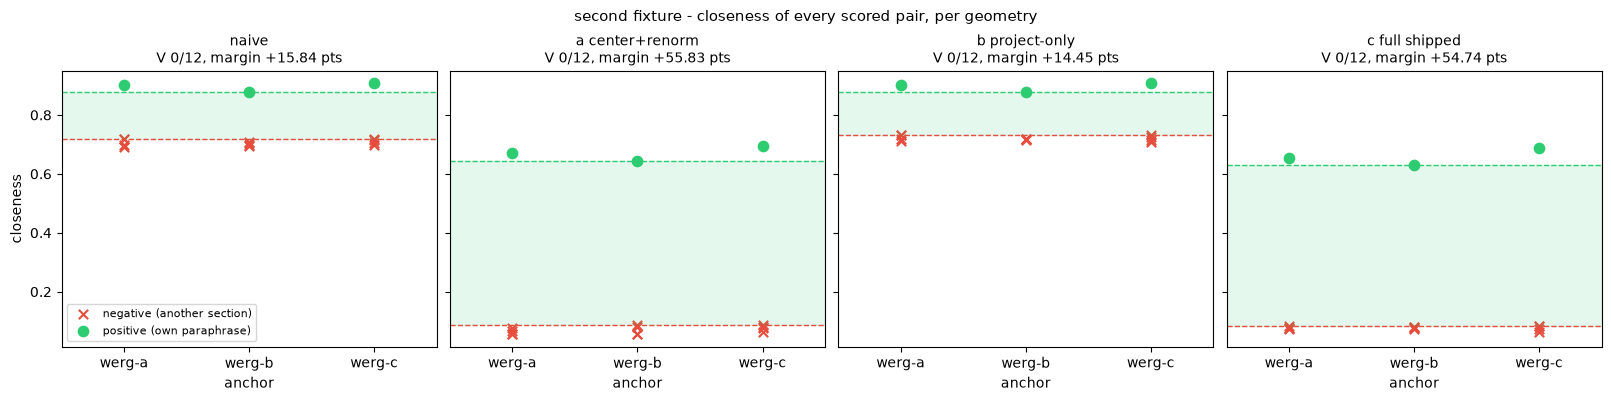

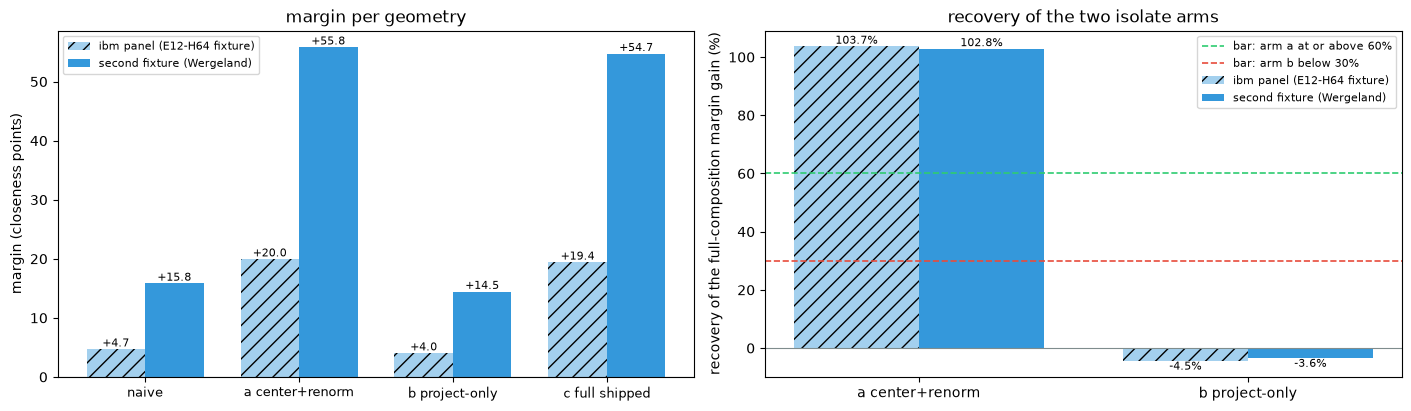

In [16]:
if PROCEED:
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.9), sharey=True, constrained_layout=True)
    for ax, name in zip(axes, GEOMS):
        r = SCORE_W[name]
        for x, anchor in enumerate(WERG_BASES):
            neg_c = [closeness(d) for k, d in r["neg"].items() if k.startswith(f"{anchor}|")]
            ax.scatter([x] * len(neg_c), neg_c, marker="x", s=45, color=C_NEG,
                       label="negative (another section)" if x == 0 else None)
            ax.scatter([x], [closeness(r["pos"][f"{anchor}|{anchor}~bt"])], marker="o", s=55, color=C_POS,
                       label="positive (own paraphrase)" if x == 0 else None)
        lo, hi = sorted((r["max_neg_closeness"], r["min_pos_closeness"]))
        ax.axhspan(lo, hi, color=C_POS if r["margin_pts"] > 0 else C_NEG, alpha=0.12)
        ax.axhline(r["min_pos_closeness"], color=C_POS, ls="--", lw=1)
        ax.axhline(r["max_neg_closeness"], color=C_NEG, ls="--", lw=1)
        ax.set_xticks(range(len(WERG_BASES)))
        ax.set_xticklabels(WERG_BASES)
        ax.set_xlim(-0.5, len(WERG_BASES) - 0.5)
        ax.set_xlabel("anchor")
        ax.set_title(f"{name}\nV {r['V']}/12, margin {r['margin_pts']:+.2f} pts", fontsize=10)
    axes[0].set_ylabel("closeness")
    axes[0].legend(fontsize=8, loc="lower left")
    fig.suptitle("second fixture - closeness of every scored pair, per geometry", fontsize=11)
    plt.show()

    fig, (ax_m, ax_r) = plt.subplots(1, 2, figsize=(14, 4.0), constrained_layout=True)
    x, w = np.arange(len(GEOMS)), 0.38
    b1 = ax_m.bar(x - w / 2, [SCORE_I[n]["margin_pts"] for n in GEOMS], w, color=C_VARIANT, alpha=0.45, hatch="//",
                  label="ibm panel (E12-H64 fixture)")
    b2 = ax_m.bar(x + w / 2, [SCORE_W[n]["margin_pts"] for n in GEOMS], w, color=C_VARIANT,
                  label="second fixture (Wergeland)")
    ax_m.bar_label(b1, fmt="%+.1f", fontsize=8)
    ax_m.bar_label(b2, fmt="%+.1f", fontsize=8)
    ax_m.axhline(0, color=C_REFERENCE, lw=0.8)
    ax_m.set_xticks(x)
    ax_m.set_xticklabels(GEOMS, fontsize=9)
    ax_m.set_ylabel("margin (closeness points)")
    ax_m.set_title("margin per geometry")
    ax_m.legend(fontsize=8)

    isolates = [ARM_A, ARM_B]
    xr = np.arange(len(isolates))
    r1 = ax_r.bar(xr - w / 2, [RECOVERY_I[n] * 100 for n in isolates], w, color=C_VARIANT, alpha=0.45, hatch="//",
                  label="ibm panel (E12-H64 fixture)")
    r2 = ax_r.bar(xr + w / 2, [RECOVERY_W[n] * 100 for n in isolates], w, color=C_VARIANT,
                  label="second fixture (Wergeland)")
    ax_r.bar_label(r1, fmt="%.1f%%", fontsize=8)
    ax_r.bar_label(r2, fmt="%.1f%%", fontsize=8)
    ax_r.axhline(BAR_RECOVERY * 100, color=C_POS, ls="--", lw=1.2, label=f"bar: arm a at or above {BAR_RECOVERY:.0%}")
    ax_r.axhline(BAR_B_MAX * 100, color=C_NEG, ls="--", lw=1.2, label=f"bar: arm b below {BAR_B_MAX:.0%}")
    ax_r.axhline(0, color=C_REFERENCE, lw=0.8)
    ax_r.set_xticks(xr)
    ax_r.set_xticklabels(isolates)
    ax_r.set_ylabel("recovery of the full-composition margin gain (%)")
    ax_r.set_title("recovery of the two isolate arms")
    ax_r.legend(fontsize=8)
    plt.show()
else:
    console.print(NOT_RUN)

## Diagnostic - the uncentered PC1 against the mean direction

Reported without a bar: the cosine between the top singular vector of the uncentered pooled matrix and the
mean direction, for the second fixture and for the ibm pool. A value near 1 means that projecting out the
top component of an uncentered matrix performs the centering. The centered PC1 is shown as the contrast.

                       pooled geometry - mean direction against the top principal component                        
┏━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃                ┃            ┃    pooled mean ┃ cos(uncentered ┃   cos(centered ┃       sv1 / sv2 ┃              ┃
┃ fixture        ┃ statements ┃           norm ┃     PC1, mean) ┃     PC1, mean) ┃      uncentered ┃ sv1 centered ┃
┡━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ second fixture │         76 │         0.9476 │       0.999999 │       0.055865 │   8.262 / 0.849 │        0.850 │
│ (Wergeland)    │            │                │                │                │                 │              │
│ ibm panel      │         98 │         0.9539 │       0.999999 │       0.021381 │   9.444 / 1.515 │        1.515 │
└────────────────┴────────────┴────────────────┴────────────────┴────────────────┴─────────────────┴──────────────┘

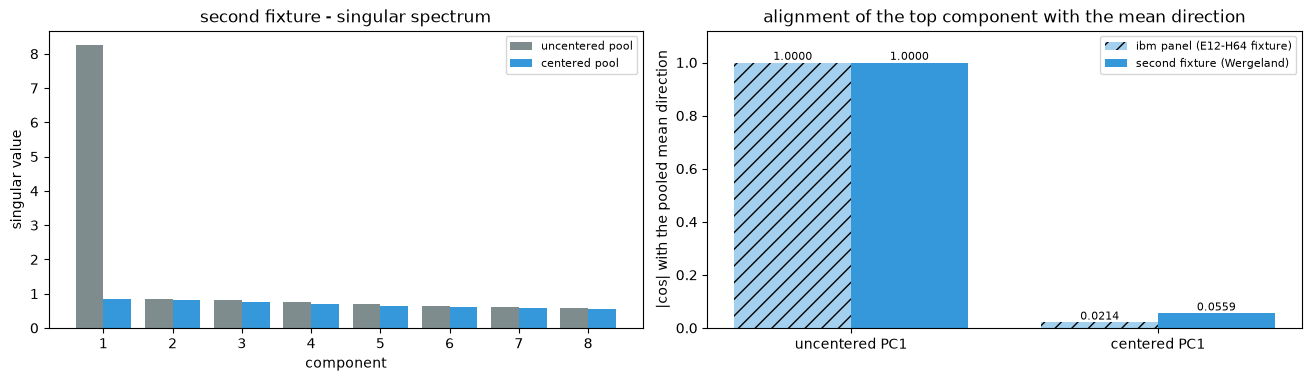

In [17]:
if PROCEED:
    GEO_W = pool_geometry(POOL_W)
    GEO_I = pool_geometry(np.concatenate([emb_i[l] for l in IBM_LABELS], 0))
    METRICS["diagnostic"] = {
        fixture: {"pooled_mean_norm": g["mean_norm"], "cos_uncentered_pc1_mean": g["cos_uncentered_pc1_mean"],
                  "cos_centered_pc1_mean": g["cos_centered_pc1_mean"],
                  "singular_values_uncentered_top3": g["sv_uncentered"][:3].tolist(),
                  "singular_values_centered_top3": g["sv_centered"][:3].tolist()}
        for fixture, g in (("second_fixture", GEO_W), ("ibm", GEO_I))
    }
    KEY.update(cos_uncentered_pc1_mean=GEO_W["cos_uncentered_pc1_mean"], cos_centered_pc1_mean=GEO_W["cos_centered_pc1_mean"],
               singular_value_1_uncentered=float(GEO_W["sv_uncentered"][0]),
               singular_value_2_uncentered=float(GEO_W["sv_uncentered"][1]),
               singular_value_1_centered=float(GEO_W["sv_centered"][0]),
               ibm_pooled_mean_norm=GEO_I["mean_norm"], ibm_cos_uncentered_pc1_mean=GEO_I["cos_uncentered_pc1_mean"])

    t = Table(title="pooled geometry - mean direction against the top principal component", header_style="bold cyan")
    for col in ("fixture", "statements", "pooled mean norm", "cos(uncentered PC1, mean)", "cos(centered PC1, mean)",
                "sv1 / sv2 uncentered", "sv1 centered"):
        t.add_column(col, justify="left" if col == "fixture" else "right")
    for fixture, g, n in (("second fixture (Wergeland)", GEO_W, POOL_W.shape[0]), ("ibm panel", GEO_I, N_IBM_STATEMENTS)):
        t.add_row(fixture, str(n), f"{g['mean_norm']:.4f}", f"{g['cos_uncentered_pc1_mean']:.6f}",
                  f"{g['cos_centered_pc1_mean']:.6f}", f"{g['sv_uncentered'][0]:.3f} / {g['sv_uncentered'][1]:.3f}",
                  f"{g['sv_centered'][0]:.3f}")
    console.print(t)

    fig, (ax_s, ax_c) = plt.subplots(1, 2, figsize=(13, 3.7), constrained_layout=True)
    idx = np.arange(1, 9)
    ax_s.bar(idx - 0.2, GEO_W["sv_uncentered"][:8], 0.4, color=C_REFERENCE, label="uncentered pool")
    ax_s.bar(idx + 0.2, GEO_W["sv_centered"][:8], 0.4, color=C_VARIANT, label="centered pool")
    ax_s.set_xticks(idx)
    ax_s.set_xlabel("component")
    ax_s.set_ylabel("singular value")
    ax_s.set_title("second fixture - singular spectrum")
    ax_s.legend(fontsize=8)
    xc, w = np.arange(2), 0.38
    c1 = ax_c.bar(xc - w / 2, [GEO_I["cos_uncentered_pc1_mean"], GEO_I["cos_centered_pc1_mean"]], w,
                  color=C_VARIANT, alpha=0.45, hatch="//", label="ibm panel (E12-H64 fixture)")
    c2 = ax_c.bar(xc + w / 2, [GEO_W["cos_uncentered_pc1_mean"], GEO_W["cos_centered_pc1_mean"]], w,
                  color=C_VARIANT, label="second fixture (Wergeland)")
    ax_c.bar_label(c1, fmt="%.4f", fontsize=8)
    ax_c.bar_label(c2, fmt="%.4f", fontsize=8)
    ax_c.set_xticks(xc)
    ax_c.set_xticklabels(["uncentered PC1", "centered PC1"])
    ax_c.set_ylim(0, 1.12)
    ax_c.set_ylabel("|cos| with the pooled mean direction")
    ax_c.set_title("alignment of the top component with the mean direction")
    ax_c.legend(fontsize=8, loc="upper right")
    plt.show()
else:
    console.print(NOT_RUN)

## Closeness saturation

`closeness()` clips to 0 at a distance of `sqrt(2)` or more, and a centered geometry can produce such
distances. The margin is defined on closeness, so a clipped pair would censor it. This section counts the
clipped pairs per geometry and recomputes the margin and the recoveries on unclipped distances:

$$\text{margin}_{\text{unclipped}} = 100 \cdot \frac{\min_{\text{negatives}} d - \max_{\text{positives}} d}{\sqrt{2}}$$

The two margins are equal whenever no margin-defining pair is clipped.

In [18]:
if PROCEED:
    SAT = {}
    for name in GEOMS:
        r = SCORE_W[name]
        top_neg = min(r["neg"], key=r["neg"].get)      # the negative that sets the margin: smallest distance
        low_pos = max(r["pos"], key=r["pos"].get)      # the positive that sets the margin: largest distance
        SAT[name] = dict(
            clipped_pairs=[k for k, d in {**r["pos"], **r["neg"]}.items() if d >= SMD_MAX],
            margin_negative=top_neg, margin_negative_distance=r["neg"][top_neg],
            margin_positive=low_pos, margin_positive_distance=r["pos"][low_pos],
            max_distance=max({**r["pos"], **r["neg"]}.values()),
            margin_unclipped_pts=(r["neg"][top_neg] - r["pos"][low_pos]) / SMD_MAX * 100.0,
        )
    _gain_unclipped = SAT[ARM_C]["margin_unclipped_pts"] - SAT[NAIVE]["margin_unclipped_pts"]
    RECOVERY_W_UNCLIPPED = {n: (SAT[n]["margin_unclipped_pts"] - SAT[NAIVE]["margin_unclipped_pts"]) / _gain_unclipped
                            for n in ARMS_W}
    N_CLIPPED = {n: len(SAT[n]["clipped_pairs"]) for n in GEOMS}
    METRICS["closeness_saturation"] = {"smd_max": SMD_MAX, "by_geometry": SAT, "recovery_unclipped": RECOVERY_W_UNCLIPPED}
    KEY.update(clipped_pairs_total=sum(N_CLIPPED.values()), arm_a_recovery_unclipped=RECOVERY_W_UNCLIPPED[ARM_A],
               arm_b_recovery_unclipped=RECOVERY_W_UNCLIPPED[ARM_B])

    t = Table(title=f"closeness saturation - distances at or above sqrt(2) = {SMD_MAX:.5f}", header_style="bold cyan")
    for col in ("geometry", "clipped", "largest distance", "margin negative", "its distance", "margin positive",
                "its distance", "margin (pts)", "unclipped margin (pts)", "unclipped recovery"):
        t.add_column(col, justify="left" if col in ("geometry", "margin negative", "margin positive") else "right")
    for name in GEOMS:
        s = SAT[name]
        t.add_row(name, f"{N_CLIPPED[name]}/15", f"{s['max_distance']:.5f}", s["margin_negative"].replace("|", " vs "),
                  f"{s['margin_negative_distance']:.5f}", s["margin_positive"].replace("|", " vs "),
                  f"{s['margin_positive_distance']:.5f}",
                  f"{SCORE_W[name]['margin_pts']:+.2f}", f"{s['margin_unclipped_pts']:+.2f}",
                  "-" if name == NAIVE else f"{RECOVERY_W_UNCLIPPED[name] * 100:.1f}%")
    console.print(t)
else:
    console.print(NOT_RUN)

                          closeness saturation - distances at or above sqrt(2) = 1.41421                           
┏━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┓
┃           ┃         ┃          ┃           ┃          ┃           ┃          ┃           ┃ unclipp… ┃           ┃
┃           ┃         ┃  largest ┃ margin    ┃      its ┃ margin    ┃      its ┃    margin ┃   margin ┃ unclipped ┃
┃ geometry  ┃ clipped ┃ distance ┃ negative  ┃ distance ┃ positive  ┃ distance ┃     (pts) ┃    (pts) ┃  recovery ┃
┡━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━┩
│ naive     │    0/15 │  0.43817 │ werg-c vs │  0.39639 │ werg-b vs │  0.17237 │    +15.84 │   +15.84 │         - │
│           │         │          │ werg-a    │          │ werg-b~bt │          │           │          │           │
│ a         │    0/15 │  1.33703 │ werg-c vs │  1.29234 │ werg-b vs │  0.50274 │    +55.83 │   +55.83 │    102.8% │
│ center+r… │         │          │ werg-b~bt │          │ werg-b~bt │          │           │          │           │
│ b         │    0/15 │  0.41045 │ werg-a vs │  0.37674 │ werg-b vs │  0.17233 │    +14.45 │   +14.45 │     -3.6% │
│ project-… │         │          │ werg-c    │          │ werg-b~bt │          │           │          │           │
│ c full    │    0/15 │  1.32380 │ werg-c vs │  1.29599 │ werg-b vs │  0.52191 │    +54.74 │   +54.74 │    100.0% │
│ shipped   │         │          │ werg-a    │          │ werg-b~bt │          │           │          │           │
└───────────┴─────────┴──────────┴───────────┴──────────┴───────────┴──────────┴───────────┴──────────┴───────────┘

## Conditioned-path reading (no bar)

The three grounded triples of `reports/E13-campaign/baseline.py`: `gold` against `1-opus`, `adv1-a` and
`adv2-b`, with the ibm source article. The shipped conditioned path pools the two documents and the source
and applies `all_but_the_top(k=1)`. Here the same pooled triple goes through arm a instead, and
`compute_source_conditioned` is then called with its own pre-pass switched off. Two checks make the
replacement exact: the shipped pre-pass reproduces the saved baseline numbers bit for bit, and arm c applied
through the same replacement route reproduces the shipped pre-pass bit for bit. The model-graded residuals
(`grd_a`, `grd_b`) take statement texts and no embedding, so the pre-pass cannot reach them and they are
not recomputed.

  conditioned path - shipped pre-pass (arm c) against arm a, 3 grounded  
                                 triples                                 
┏━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ triple      ┃ field       ┃ shipped (arm c) ┃    arm a ┃ |difference| ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ gold|v1     │ d_sel       │        0.310164 │ 0.132115 │     0.178049 │
│ gold|v1     │ residual_a  │        1.234874 │ 1.196268 │     0.038606 │
│ gold|v1     │ residual_b  │        1.219940 │ 1.188187 │     0.031753 │
│ gold|v1     │ closeness_a │        0.126812 │ 0.154111 │     0.027299 │
│ gold|v1     │ closeness_b │        0.137372 │ 0.159825 │     0.022453 │
│ gold|adv1-a │ d_sel       │        0.805617 │ 0.397477 │     0.408140 │
│ gold|adv1-a │ residual_a  │        1.229848 │ 1.185696 │     0.044152 │
│ gold|adv1-a │ residual_b  │        1.356195 │ 1.273238 │     0.082957 │
│ gold|adv1-a │ closeness_a │        0.130366 │ 0.161586 │     0.031220 │
│ gold|adv1-a │ closeness_b │        0.041025 │ 0.099685 │     0.058659 │
│ gold|adv2-b │ d_sel       │        0.413829 │ 0.136424 │     0.277405 │
│ gold|adv2-b │ residual_a  │        1.232753 │ 1.175941 │     0.056811 │
│ gold|adv2-b │ residual_b  │        1.359365 │ 1.256751 │     0.102614 │
│ gold|adv2-b │ closeness_a │        0.128312 │ 0.168484 │     0.040172 │
│ gold|adv2-b │ closeness_b │        0.038784 │ 0.111343 │     0.072559 │
└─────────────┴─────────────┴─────────────────┴──────────┴──────────────┘
                                 conditioned path - separation readings per triple                                 
┏━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃             ┃               ┃             ┃                 ┃           closeness_a - ┃           closeness_a - ┃
┃ triple      ┃ d_sel shipped ┃ d_sel arm a ┃ arm a / shipped ┃     closeness_b shipped ┃       closeness_b arm a ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ gold|v1     │        0.3102 │      0.1321 │           0.426 │                 -0.0106 │                 -0.0057 │
│ gold|adv1-a │        0.8056 │      0.3975 │           0.493 │                 +0.0893 │                 +0.0619 │
│ gold|adv2-b │        0.4138 │      0.1364 │           0.330 │                 +0.0895 │                 +0.0571 │
└─────────────┴───────────────┴─────────────┴─────────────────┴─────────────────────────┴─────────────────────────┘
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ largest |closeness difference| = 0.072559 (7.26 closeness points) at gold|adv2-b, closeness_b                   │
│ largest |d_sel difference| = 0.408140 | largest |residual difference| = 0.102614 | arm a residuals at or above  │
│ sqrt(2): 0/6                                                                                                    │
│ triples ordered by d_sel, shipped: gold|v1 < gold|adv2-b < gold|adv1-a | arm a: gold|v1 < gold|adv2-b <         │
│ gold|adv1-a                                                                                                     │
│ shipped pre-pass equals the saved baseline bit for bit: True | arm c through the replacement route equals the   │
│ shipped pre-pass bit for bit: True | source statements: 70                                                      │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

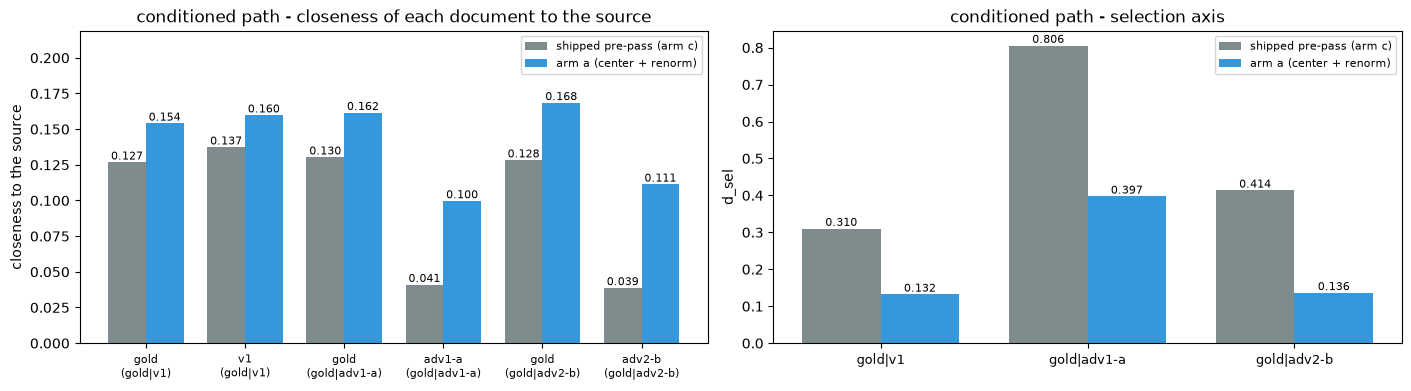

In [19]:
if PROCEED:
    source_emb = dd.embed(IBM_DIR / "source" / "source-article.md")       # the source through the shipped reader
    N_SOURCE = len(source_emb)
    COND_FIELDS = ("d_sel", "residual_a", "residual_b", "closeness_a", "closeness_b")
    COND = {}
    for a, b in GROUNDED:
        triple = {"a": emb_i[a], "b": emb_i[b], "s": source_emb}
        shipped = compute_source_conditioned(triple["a"], triple["b"], triple["s"])       # shipped pre-pass, anisotropy on
        arms = three_arms(triple)                                                         # pool = a + b + source, as shipped
        via_c = compute_source_conditioned(arms[ARM_C]["a"], arms[ARM_C]["b"], arms[ARM_C]["s"], anisotropy=False)
        via_a = compute_source_conditioned(arms[ARM_A]["a"], arms[ARM_A]["b"], arms[ARM_A]["s"], anisotropy=False)
        saved = baseline["grounded"][f"{IBM_STEM[a]}|{IBM_STEM[b]}"]
        COND[f"{a}|{b}"] = dict(
            shipped={f: getattr(shipped, f) for f in COND_FIELDS},
            arm_a={f: getattr(via_a, f) for f in COND_FIELDS},
            abs_diff={f: abs(getattr(via_a, f) - getattr(shipped, f)) for f in COND_FIELDS},
            shipped_equals_baseline=all(hexf(getattr(shipped, f)) == hexf(saved[f]) for f in COND_FIELDS),
            replacement_route_equals_shipped=all(hexf(getattr(via_c, f)) == hexf(getattr(shipped, f)) for f in COND_FIELDS),
            n_statements_source=shipped.n_statements_source,
            d_sel_ratio_arm_a_over_shipped=via_a.d_sel / shipped.d_sel,
            closeness_gap_shipped=shipped.closeness_a - shipped.closeness_b,      # anchor minus the compared document
            closeness_gap_arm_a=via_a.closeness_a - via_a.closeness_b,
        )

    _closeness = [(c["abs_diff"][f], t, f) for t, c in COND.items() for f in ("closeness_a", "closeness_b")]
    COND_MAX_CLOSENESS_DIFF, COND_MAX_AT_TRIPLE, COND_MAX_AT_FIELD = max(_closeness)
    COND_MAX_DSEL_DIFF = max(c["abs_diff"]["d_sel"] for c in COND.values())
    COND_MAX_RESIDUAL_DIFF = max(c["abs_diff"][f] for c in COND.values() for f in ("residual_a", "residual_b"))
    COND_CLIPPED_ARM_A = sum(c["arm_a"][f] >= SMD_MAX for c in COND.values() for f in ("residual_a", "residual_b"))
    COND_BASELINE_OK = all(c["shipped_equals_baseline"] for c in COND.values())
    COND_ROUTE_OK = all(c["replacement_route_equals_shipped"] for c in COND.values())
    COND_DSEL_ORDER_SHIPPED = sorted(COND, key=lambda k: COND[k]["shipped"]["d_sel"])
    COND_DSEL_ORDER_ARM_A = sorted(COND, key=lambda k: COND[k]["arm_a"]["d_sel"])
    COND_DSEL_RATIOS = [c["d_sel_ratio_arm_a_over_shipped"] for c in COND.values()]
    METRICS["conditioned_path"] = {
        "triples": COND, "max_abs_closeness_diff": COND_MAX_CLOSENESS_DIFF,
        "max_abs_closeness_diff_pts": COND_MAX_CLOSENESS_DIFF * 100.0,
        "max_abs_closeness_diff_at": f"{COND_MAX_AT_TRIPLE} {COND_MAX_AT_FIELD}",
        "max_abs_d_sel_diff": COND_MAX_DSEL_DIFF, "max_abs_residual_diff": COND_MAX_RESIDUAL_DIFF,
        "arm_a_residuals_at_or_above_sqrt2": int(COND_CLIPPED_ARM_A),
        "shipped_equals_baseline": COND_BASELINE_OK, "replacement_route_equals_shipped": COND_ROUTE_OK,
        "d_sel_order_shipped": COND_DSEL_ORDER_SHIPPED, "d_sel_order_arm_a": COND_DSEL_ORDER_ARM_A,
        "d_sel_order_preserved": COND_DSEL_ORDER_SHIPPED == COND_DSEL_ORDER_ARM_A,
        "d_sel_ratio_arm_a_over_shipped_min": min(COND_DSEL_RATIOS), "d_sel_ratio_arm_a_over_shipped_max": max(COND_DSEL_RATIOS),
    }
    KEY.update(conditioned_max_abs_closeness_diff=COND_MAX_CLOSENESS_DIFF,
               conditioned_max_abs_closeness_diff_pts=COND_MAX_CLOSENESS_DIFF * 100.0,
               conditioned_max_abs_d_sel_diff=COND_MAX_DSEL_DIFF,
               conditioned_max_abs_residual_diff=COND_MAX_RESIDUAL_DIFF,
               conditioned_d_sel_ratio_min=min(COND_DSEL_RATIOS), conditioned_d_sel_ratio_max=max(COND_DSEL_RATIOS),
               conditioned_d_sel_order_preserved=COND_DSEL_ORDER_SHIPPED == COND_DSEL_ORDER_ARM_A)

    t = Table(title="conditioned path - shipped pre-pass (arm c) against arm a, 3 grounded triples", header_style="bold cyan")
    for col in ("triple", "field", "shipped (arm c)", "arm a", "|difference|"):
        t.add_column(col, justify="left" if col in ("triple", "field") else "right")
    for triple, c in COND.items():
        for f in COND_FIELDS:
            t.add_row(triple, f, f"{c['shipped'][f]:.6f}", f"{c['arm_a'][f]:.6f}", f"{c['abs_diff'][f]:.6f}")
    sep = Table(title="conditioned path - separation readings per triple", header_style="bold cyan")
    for col in ("triple", "d_sel shipped", "d_sel arm a", "arm a / shipped", "closeness_a - closeness_b shipped",
                "closeness_a - closeness_b arm a"):
        sep.add_column(col, justify="left" if col == "triple" else "right")
    for triple, c in COND.items():
        sep.add_row(triple, f"{c['shipped']['d_sel']:.4f}", f"{c['arm_a']['d_sel']:.4f}",
                    f"{c['d_sel_ratio_arm_a_over_shipped']:.3f}", f"{c['closeness_gap_shipped']:+.4f}",
                    f"{c['closeness_gap_arm_a']:+.4f}")
    console.print(Group(t, sep, Panel(
        f"largest |closeness difference| = [bold]{COND_MAX_CLOSENESS_DIFF:.6f}[/bold] "
        f"({COND_MAX_CLOSENESS_DIFF * 100:.2f} closeness points) at {COND_MAX_AT_TRIPLE}, {COND_MAX_AT_FIELD}\n"
        f"largest |d_sel difference| = [bold]{COND_MAX_DSEL_DIFF:.6f}[/bold] | largest |residual difference| = "
        f"{COND_MAX_RESIDUAL_DIFF:.6f} | arm a residuals at or above sqrt(2): {COND_CLIPPED_ARM_A}/6\n"
        f"triples ordered by d_sel, shipped: {' < '.join(COND_DSEL_ORDER_SHIPPED)} | arm a: {' < '.join(COND_DSEL_ORDER_ARM_A)}\n"
        f"shipped pre-pass equals the saved baseline bit for bit: {COND_BASELINE_OK} | arm c through the replacement "
        f"route equals the shipped pre-pass bit for bit: {COND_ROUTE_OK} | source statements: {N_SOURCE}",
        border_style="cyan")))

    fig, (ax_c, ax_d) = plt.subplots(1, 2, figsize=(14, 3.8), constrained_layout=True)
    labels = [f"{t.split('|')[i]}\n({t})" for t in COND for i in (0, 1)]
    ship = [c["shipped"][f] for c in COND.values() for f in ("closeness_a", "closeness_b")]
    arma = [c["arm_a"][f] for c in COND.values() for f in ("closeness_a", "closeness_b")]
    x, w = np.arange(len(labels)), 0.38
    s1 = ax_c.bar(x - w / 2, ship, w, color=C_REFERENCE, label="shipped pre-pass (arm c)")
    s2 = ax_c.bar(x + w / 2, arma, w, color=C_VARIANT, label="arm a (center + renorm)")
    ax_c.bar_label(s1, fmt="%.3f", fontsize=8)
    ax_c.bar_label(s2, fmt="%.3f", fontsize=8)
    ax_c.set_xticks(x)
    ax_c.set_xticklabels(labels, fontsize=8)
    ax_c.set_ylim(0, max(ship + arma) * 1.3)
    ax_c.set_ylabel("closeness to the source")
    ax_c.set_title("conditioned path - closeness of each document to the source")
    ax_c.legend(fontsize=8)
    xd = np.arange(len(COND))
    d1 = ax_d.bar(xd - w / 2, [c["shipped"]["d_sel"] for c in COND.values()], w, color=C_REFERENCE, label="shipped pre-pass (arm c)")
    d2 = ax_d.bar(xd + w / 2, [c["arm_a"]["d_sel"] for c in COND.values()], w, color=C_VARIANT, label="arm a (center + renorm)")
    ax_d.bar_label(d1, fmt="%.3f", fontsize=8)
    ax_d.bar_label(d2, fmt="%.3f", fontsize=8)
    ax_d.set_xticks(xd)
    ax_d.set_xticklabels(list(COND), fontsize=9)
    ax_d.set_ylabel("d_sel")
    ax_d.set_title("conditioned path - selection axis")
    ax_d.legend(fontsize=8)
    plt.show()
else:
    console.print(NOT_RUN)

## Guardrails

Each guardrail is measured. `V` is counted per scored geometry on both fixtures. The raw embeddings and the
shipped default-path `smd` and `order_gap` are compared byte for byte with the snapshots taken before any
arm ran, and the 55 ibm pairs are compared with the baseline captured at commit `bd0002e`. The metric
property is read three ways per geometry: unit norms, `cost = sqrt(2 - 2cos)`, and the triangle inequality
over every statement triple. `git status` reports whether `src/` and `tests/` are unmodified.

In [20]:
if PROCEED:
    # 1 - V per scored geometry
    V_W = {n: SCORE_W[n]["V"] for n in GEOMS}
    V_I = {n: SCORE_I[n]["V"] for n in GEOMS}
    V_SANITY_ZERO = all(SCORE_I[n]["V"] == 0 for n in SANITY_REGISTERED)       # the standing V 0/24 on the sanity rows

    # 2 - raw embeddings byte-identical after every arm
    RAW_W_UNCHANGED = raw_unchanged(emb_w, RAW_W_BYTES) and all(RAW_W_UNCHANGED_AFTER.values())
    RAW_I_UNCHANGED = raw_unchanged(emb_i, RAW_I_BYTES)

    # 3 - default path bit-identical: before against after, and after against the captured 1.1.5 baseline
    DEFAULT_W_AFTER = default_path(emb_w, WERG_PAIRS)
    DEFAULT_I_AFTER = default_path(emb_stem, IBM_PAIRS)
    DEFAULT_W_IDENTICAL = DEFAULT_W_AFTER == DEFAULT_W_BEFORE
    DEFAULT_I_IDENTICAL = DEFAULT_I_AFTER == DEFAULT_I_BEFORE
    BASELINE_SMD_EQUAL = sum(DEFAULT_I_AFTER[k][0] == hexf(baseline["pairs"][k]["semantic"]["smd"]) for k in DEFAULT_I_AFTER)
    BASELINE_GAP_EQUAL = sum(DEFAULT_I_AFTER[k][1] == hexf(baseline["pairs"][k]["structural"]["order_gap"]) for k in DEFAULT_I_AFTER)
    DEFAULT_PATH_OK = bool(DEFAULT_W_IDENTICAL and DEFAULT_I_IDENTICAL
                           and BASELINE_SMD_EQUAL == len(IBM_PAIRS) and BASELINE_GAP_EQUAL == len(IBM_PAIRS))

    # 4 - metric property per geometry, both fixtures; the naive rows are the shipped reference
    METRIC = {f"{fixture} - {name}": metric_property(eb)
              for fixture, geoms in (("second fixture", {NAIVE: emb_w, **ARMS_W}), ("ibm", {NAIVE: emb_i, **ARMS_I}))
              for name, eb in geoms.items()}
    METRIC_OK = all(m["holds"] for m in METRIC.values())
    COST_ID_FLOAT32_WITHIN_TOL = {k: bool(m["max_cost_identity_dev_float32"] <= COST_ID_TOL) for k, m in METRIC.items()}

    # 5 - shipped source and tests unmodified; docs/ is listed for the record
    tree = subprocess.run(["git", "-C", str(ROOT), "status", "--porcelain", "src", "tests"],
                          capture_output=True, text=True).stdout.strip()
    docs_tree = subprocess.run(["git", "-C", str(ROOT), "status", "--porcelain", "docs"],
                               capture_output=True, text=True).stdout.strip()
    SRC_UNTOUCHED = tree == ""

    GUARDRAILS_OK = bool(V_SANITY_ZERO and RAW_W_UNCHANGED and RAW_I_UNCHANGED and DEFAULT_PATH_OK
                         and METRIC_OK and SRC_UNTOUCHED)
    METRICS["guardrails"] = {
        "V_second_fixture": {n: f"{v}/12" for n, v in V_W.items()},
        "V_ibm": {n: f"{v}/24" for n, v in V_I.items()}, "V_ibm_sanity_rows_zero": V_SANITY_ZERO,
        "raw_embeddings_byte_identical_second_fixture": RAW_W_UNCHANGED,
        "raw_embeddings_byte_identical_after_each_arm": RAW_W_UNCHANGED_AFTER,
        "raw_embeddings_byte_identical_ibm": RAW_I_UNCHANGED,
        "default_path_second_fixture_before_equals_after": DEFAULT_W_IDENTICAL,
        "default_path_second_fixture_pairs": len(DEFAULT_W_AFTER),
        "default_path_ibm_before_equals_after": DEFAULT_I_IDENTICAL,
        "default_path_ibm_smd_equal_to_baseline": f"{BASELINE_SMD_EQUAL}/{len(IBM_PAIRS)}",
        "default_path_ibm_order_gap_equal_to_baseline": f"{BASELINE_GAP_EQUAL}/{len(IBM_PAIRS)}",
        "default_path_bit_identical": DEFAULT_PATH_OK,
        "metric_property": METRIC, "metric_property_holds": METRIC_OK,
        "cost_identity_float32_within_1e-6": COST_ID_FLOAT32_WITHIN_TOL,
        "git_status_src_tests": tree, "src_tests_untouched": SRC_UNTOUCHED, "git_status_docs": docs_tree,
        "all_hold": GUARDRAILS_OK,
    }

    def yn(b: bool) -> str:
        return "[green]yes[/green]" if b else "[red]no[/red]"

    t = Table(title="guardrails", header_style="bold cyan")
    for col in ("guardrail", "reading", "holds"):
        t.add_column(col)
    t.add_row("V - second fixture", " | ".join(f"{n} {v}/12" for n, v in V_W.items()),
              yn(V_W[ARM_A] == 0 and V_W[ARM_C] == 0))
    t.add_row("V - ibm sanity rows (standing 0/24)", " | ".join(f"{n} {v}/24" for n, v in V_I.items()), yn(V_SANITY_ZERO))
    t.add_row("raw embeddings byte-identical", f"second fixture {POOL_W.shape[0]} statements, after each arm and at the end | "
              f"ibm {N_IBM_STATEMENTS} statements", yn(RAW_W_UNCHANGED and RAW_I_UNCHANGED))
    t.add_row("default path - second fixture", f"smd and order_gap of {len(DEFAULT_W_AFTER)} pairs, before against after",
              yn(DEFAULT_W_IDENTICAL))
    t.add_row("default path - ibm", f"smd and order_gap of {len(IBM_PAIRS)} pairs, before against after | against the bd0002e "
              f"baseline: smd {BASELINE_SMD_EQUAL}/{len(IBM_PAIRS)}, order_gap {BASELINE_GAP_EQUAL}/{len(IBM_PAIRS)}",
              yn(DEFAULT_I_IDENTICAL and BASELINE_SMD_EQUAL == len(IBM_PAIRS) and BASELINE_GAP_EQUAL == len(IBM_PAIRS)))
    for name, m in METRIC.items():
        t.add_row(f"metric property - {name}",
                  f"max |‖x‖-1| {m['max_unit_norm_dev']:.1e} | max |C - sqrt(2-2cos)| float64 {m['max_cost_identity_dev_float64']:.1e}, "
                  f"float32 arrays {m['max_cost_identity_dev_float32']:.1e} | max triangle slack {m['max_triangle_slack']:+.1e}",
                  yn(m["holds"]))
    t.add_row("src/ and tests/ unmodified", tree or "(git status reports no modification)", yn(SRC_UNTOUCHED))
    t.add_row("docs/ (for the record, not written by this notebook)", docs_tree or "(no modification)", "-")
    console.print(Group(t, Panel(f"guardrails hold: [bold]{GUARDRAILS_OK}[/bold]",
                                 border_style="green" if GUARDRAILS_OK else "red")))
else:
    console.print(NOT_RUN)

                                                    guardrails                                                     
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ guardrail                                          ┃ reading                                            ┃ holds ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ V - second fixture                                 │ naive 0/12 | a center+renorm 0/12 | b project-only │ yes   │
│                                                    │ 0/12 | c full shipped 0/12                         │       │
│ V - ibm sanity rows (standing 0/24)                │ naive 0/24 | a center+renorm 0/24 | b project-only │ yes   │
│                                                    │ 0/24 | c full shipped 0/24                         │       │
│ raw embeddings byte-identical                      │ second fixture 76 statements, after each arm and   │ yes   │
│                                                    │ at the end | ibm 98 statements                     │       │
│ default path - second fixture                      │ smd and order_gap of 15 pairs, before against      │ yes   │
│                                                    │ after                                              │       │
│ default path - ibm                                 │ smd and order_gap of 55 pairs, before against      │ yes   │
│                                                    │ after | against the bd0002e baseline: smd 55/55,   │       │
│                                                    │ order_gap 55/55                                    │       │
│ metric property - second fixture - naive           │ max |‖x‖-1| 1.2e-07 | max |C - sqrt(2-2cos)|       │ yes   │
│                                                    │ float64 3.9e-08, float32 arrays 5.8e-04 | max      │       │
│                                                    │ triangle slack +1.2e-15                            │       │
│ metric property - second fixture - a center+renorm │ max |‖x‖-1| 1.2e-07 | max |C - sqrt(2-2cos)|       │ yes   │
│                                                    │ float64 4.9e-08, float32 arrays 5.7e-04 | max      │       │
│                                                    │ triangle slack +2.2e-16                            │       │
│ metric property - second fixture - b project-only  │ max |‖x‖-1| 1.8e-07 | max |C - sqrt(2-2cos)|       │ yes   │
│                                                    │ float64 5.2e-08, float32 arrays 7.7e-04 | max      │       │
│                                                    │ triangle slack +0.0e+00                            │       │
│ metric property - second fixture - c full shipped  │ max |‖x‖-1| 1.2e-07 | max |C - sqrt(2-2cos)|       │ yes   │
│                                                    │ float64 4.5e-08, float32 arrays 5.9e-04 | max      │       │
│                                                    │ triangle slack +0.0e+00                            │       │
│ metric property - ibm - naive                      │ max |‖x‖-1| 1.8e-07 | max |C - sqrt(2-2cos)|       │ yes   │
│                                                    │ float64 4.5e-08, float32 arrays 5.7e-04 | max      │       │
│                                                    │ triangle slack +0.0e+00                            │       │
│ metric property - ibm - a center+renorm            │ max |‖x‖-1| 1.2e-07 | max |C - sqrt(2-2cos)|       │ yes   │
│                                                    │ float64 4.7e-08, float32 arrays 6.2e-04 | max      │       │
│                                                    │ triangle slack +0.0e+00                            │       │
│ metric property - ibm - b project-only             │ max |‖x‖-1| 2.4e-07 | max |C - sqrt(2-2cos)|       │ yes   │
│                                                    │ f

## Prediction check

The record's prediction has five clauses. Each one is scored on its own line. The direction is the
hypothesis statement itself: centering plus renormalisation recovers at least 60% of the full-composition
gain while the projection isolate recovers less than 30%.

In [21]:
if PROCEED:
    PRED = {
        "pooled mean norm": (f"> {PRED_MIN_MEAN_NORM}", f"{MEAN_NORM_W:.4f}", bool(MEAN_NORM_W > PRED_MIN_MEAN_NORM)),
        "cos(uncentered PC1, mean direction)": (f">= {PRED_MIN_COS}", f"{GEO_W['cos_uncentered_pc1_mean']:.6f}",
                                                bool(GEO_W["cos_uncentered_pc1_mean"] >= PRED_MIN_COS)),
        "arm a recovery": (f">= {PRED_MIN_A_RECOVERY:.0%}", f"{RECOVERY_W[ARM_A] * 100:.1f}%",
                           bool(RECOVERY_W[ARM_A] >= PRED_MIN_A_RECOVERY)),
        "arm b recovery": (f"{PRED_B_BAND[0]:+.0%} .. {PRED_B_BAND[1]:+.0%}", f"{RECOVERY_W[ARM_B] * 100:.1f}%",
                           bool(PRED_B_BAND[0] <= RECOVERY_W[ARM_B] <= PRED_B_BAND[1])),
        "V in arms a and c": ("0/12 and 0/12", f"{SCORE_W[ARM_A]['V']}/12 and {SCORE_W[ARM_C]['V']}/12",
                              bool(SCORE_W[ARM_A]["V"] == 0 and SCORE_W[ARM_C]["V"] == 0)),
    }
    PRED_CLAUSES_HELD = sum(v[2] for v in PRED.values())
    PRED_DIRECTION_HELD = bool(RECOVERY_W[ARM_A] >= BAR_RECOVERY and RECOVERY_W[ARM_B] < BAR_B_MAX)
    METRICS["prediction_check"] = {
        "clauses": {k: {"predicted": v[0], "observed": v[1], "held": v[2]} for k, v in PRED.items()},
        "clauses_held": f"{PRED_CLAUSES_HELD}/{len(PRED)}", "direction_held": PRED_DIRECTION_HELD,
    }

    t = Table(title="registered prediction, clause by clause", header_style="bold cyan")
    for col in ("clause", "predicted", "observed", "held"):
        t.add_column(col)
    for k, (predicted, observed, held) in PRED.items():
        t.add_row(k, predicted, observed, "[green]yes[/green]" if held else "[red]no[/red]")
    console.print(Group(t, Panel(
        f"clauses held: [bold]{PRED_CLAUSES_HELD}/{len(PRED)}[/bold] | direction held (arm a at or above "
        f"{BAR_RECOVERY:.0%}, arm b below {BAR_B_MAX:.0%}): [bold]{PRED_DIRECTION_HELD}[/bold]",
        border_style="green" if PRED_DIRECTION_HELD else "red")))
else:
    console.print(NOT_RUN)

                   registered prediction, clause by clause                    
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━┓
┃ clause                              ┃ predicted     ┃ observed      ┃ held ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━┩
│ pooled mean norm                    │ > 0.9         │ 0.9476        │ yes  │
│ cos(uncentered PC1, mean direction) │ >= 0.999      │ 0.999999      │ yes  │
│ arm a recovery                      │ >= 90%        │ 102.8%        │ yes  │
│ arm b recovery                      │ -15% .. +15%  │ -3.6%         │ yes  │
│ V in arms a and c                   │ 0/12 and 0/12 │ 0/12 and 0/12 │ yes  │
└─────────────────────────────────────┴───────────────┴───────────────┴──────┘
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ clauses held: 5/5 | direction held (arm a at or above 60%, arm b below 30%): True                               │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Acceptance bar

The registered bar, the E12-H64 bar applied to the second fixture: the attribution reproduces iff exactly
one isolate arm reaches at least 60% of the full-composition margin gain at `V` 0/12, that arm is arm a,
and arm b stays below 30%. Arm c is the denominator and is 100% by definition, so the count runs over the
two isolate arms.

In [22]:
if PROCEED:
    ISOLATES = [ARM_A, ARM_B]
    REACHING = [n for n in ISOLATES if RECOVERY_W[n] >= BAR_RECOVERY and SCORE_W[n]["V"] == 0]
    ATTRIBUTION_REPRODUCES = bool(REACHING == [ARM_A] and RECOVERY_W[ARM_B] < BAR_B_MAX)
    BAR_MET = bool(ATTRIBUTION_REPRODUCES and GUARDRAILS_OK)
    METRICS["acceptance"] = {
        "bar": "exactly one isolate arm >= 60% of the full-composition margin gain at V 0/12, that arm is a, arm b < 30%; "
               "guardrails hold",
        "met": BAR_MET, "attribution_reproduces": ATTRIBUTION_REPRODUCES, "guardrails_hold": GUARDRAILS_OK,
        "readings": {
            "full_composition_margin_gain_pts": FULL_GAIN_W,
            "arm_a_recovery": RECOVERY_W[ARM_A], "arm_b_recovery": RECOVERY_W[ARM_B],
            "arm_a_V": SCORE_W[ARM_A]["V"], "arm_b_V": SCORE_W[ARM_B]["V"], "arm_c_V": SCORE_W[ARM_C]["V"],
            "arms_reaching_bar": len(REACHING), "arm_reaching_bar": ", ".join(REACHING) or "none",
            "arm_b_below_30pct": bool(RECOVERY_W[ARM_B] < BAR_B_MAX),
        },
    }

    t = Table(title="acceptance bar - margin-gain recovery of the isolate arms", header_style="bold cyan")
    for col in ("arm", "margin (pts)", "gain (pts)", "recovery", "V", "requirement", "met"):
        t.add_column(col, justify="left" if col in ("arm", "requirement", "met") else "right")
    for n, requirement, met in ((ARM_A, f">= {BAR_RECOVERY:.0%} at V 0/12", ARM_A in REACHING),
                                (ARM_B, f"< {BAR_B_MAX:.0%}", RECOVERY_W[ARM_B] < BAR_B_MAX)):
        r = SCORE_W[n]
        t.add_row(n, f"{r['margin_pts']:+.2f}", f"{r['margin_pts'] - naive_w['margin_pts']:+.2f}",
                  f"{RECOVERY_W[n] * 100:.1f}%", f"{r['V']}/12", requirement,
                  "[green]yes[/green]" if met else "[red]no[/red]")
    console.print(Group(t, Panel(
        f"isolate arms reaching {BAR_RECOVERY:.0%} at V 0/12: {', '.join(REACHING) or 'none'}\n"
        f"attribution reproduces: [bold]{ATTRIBUTION_REPRODUCES}[/bold] | guardrails hold: [bold]{GUARDRAILS_OK}[/bold] | "
        f"bar met: [bold]{BAR_MET}[/bold]",
        title="E14-H75 acceptance", border_style="green" if BAR_MET else "red")))
else:
    console.print(NOT_RUN)

                acceptance bar - margin-gain recovery of the isolate arms                 
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━┓
┃ arm             ┃ margin (pts) ┃ gain (pts) ┃ recovery ┃    V ┃ requirement      ┃ met ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━┩
│ a center+renorm │       +55.83 │     +39.99 │   102.8% │ 0/12 │ >= 60% at V 0/12 │ yes │
│ b project-only  │       +14.45 │      -1.39 │    -3.6% │ 0/12 │ < 30%            │ yes │
└─────────────────┴──────────────┴────────────┴──────────┴──────┴──────────────────┴─────┘
╭────────────────────────────────────────────── E14-H75 acceptance ───────────────────────────────────────────────╮
│ isolate arms reaching 60% at V 0/12: a center+renorm                                                            │
│ attribution reproduces: True | guardrails hold: True | bar met: True                                            │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Verdict and metrics JSON

The verdict follows the campaign vocabulary in a fixed order: a fired kill-gate gives `Killed-at-gate`; a
failed harness sanity check or a failed guardrail gives `Blocked`; a reproduced attribution gives
`Confirmed`; otherwise the hypothesis is `Refuted`. The key numbers are printed at full precision so that
every number of the campaign result JSON is copied from an output of this run, and every measured number is
written to `reports/E14-H75-centering-attribution-transfer-metrics.json`.

In [23]:
if not GATE_PASSED:
    VERDICT = "Killed-at-gate"
elif not SANITY_PASSED:
    VERDICT = "Blocked"
elif not GUARDRAILS_OK:
    VERDICT = "Blocked"
elif ATTRIBUTION_REPRODUCES:
    VERDICT = "Confirmed"
else:
    VERDICT = "Refuted"

METRICS["verdict"] = VERDICT
METRICS["result_key_numbers"] = KEY
METRICS_PATH.write_text(json.dumps(METRICS, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"verdict = {VERDICT}\n"
      f"wrote {METRICS_PATH.relative_to(ROOT)} ({METRICS_PATH.stat().st_size} bytes)\n"
      f"key_numbers =\n{json.dumps(KEY, indent=2)}\n"
      f"acceptance =\n{json.dumps(METRICS.get('acceptance', {}), indent=2)}\n"
      f"kill_gate =\n{json.dumps(METRICS['kill_gate'], indent=2)}\n"
      f"sanity_check rows =\n{json.dumps(METRICS.get('sanity_check', {}).get('rows', {}), indent=2)}")

verdict = Confirmed
wrote reports/E14-H75-centering-attribution-transfer-metrics.json (22337 bytes)
key_numbers =
{
  "pooled_mean_norm": 0.9475964903831482,
  "naive_margin_pts": 15.840281221945318,
  "arm_c_margin_pts": 54.73572979318323,
  "full_composition_margin_gain_pts": 38.895448571237914,
  "n_statements": 76,
  "n_documents": 6,
  "ibm_naive_margin_pts": 4.708317407970153,
  "ibm_arm_a_margin_pts": 19.952554955749292,
  "ibm_arm_b_margin_pts": 4.044454232474026,
  "ibm_arm_c_margin_pts": 19.414396463424644,
  "ibm_arm_a_recovery": 1.0365942880012633,
  "ibm_arm_b_recovery": -0.04514209212345421,
  "ibm_sanity_max_rel_delta": 0.00035723822289747506,
  "naive_V": 0,
  "naive_dprime": 16.97988870838797,
  "arm_a_margin_pts": 55.8332065424265,
  "arm_a_V": 0,
  "arm_a_dprime": 35.88973585875125,
  "arm_b_margin_pts": 14.454066482903416,
  "arm_b_V": 0,
  "arm_b_dprime": 16.41734142118946,
  "arm_c_V": 0,
  "arm_c_dprime": 34.70953241254488,
  "arm_a_gain_pts": 39.992925320481184,

## Conclusions

**The attribution reproduces on the second fixture.** On the three Wergeland sections and their
back-translation paraphrases, mean-centering plus re-L2-normalisation (arm a) recovers 102.8% of the margin
gain of the shipped `all_but_the_top(k=1)`, and the projection isolate (arm b) recovers -3.6%. Arm a is the
only isolate arm at or above 60%, it reads `V` 0/12, and arm b is below 30%. The registered bar is met and
all five prediction clauses held. Verdict: **Confirmed**.

**Kill-gate** - both readings passed

- Pooled mean norm 0.9476 against a kill threshold of 0.15
- Full-composition margin gain +38.90 closeness points (naive +15.84 → full composition +54.74) against a kill threshold of +1.0

**Harness sanity check** - passed

- ibm margins on this re-encode: naive +4.7083 (registered +4.71, 0.04% off), arm a +19.9526 (+19.95, 0.01% off), full composition +19.4144 (+19.41, 0.02% off), against a 5% tolerance; `V` 0/24 in all four ibm geometries
- Against the E12-H64 full-precision rows, the naive, arm a and arm b margins differ by 0.00e+00 and the arm c margin by 2.13e-14 points: the three-arm code scored here is the E12-H64 code
- 98 ibm statements, the E12-H64 count. The shipped default-path `smd` and `order_gap` of all 55 ibm pairs equal the baseline captured at `bd0002e` bit for bit

**Registered experiment** - 76 pooled statements, 3 positives, 12 negatives

| geometry | V | margin (pts) | gain (pts) | recovery | d' |
|---|---|---|---|---|---|
| naive | 0/12 | +15.84 | - | - | 16.98 |
| a center+renorm | 0/12 | +55.83 | +39.99 | 102.8% | 35.89 |
| b project-only | 0/12 | +14.45 | -1.39 | -3.6% | 16.42 |
| c full shipped | 0/12 | +54.74 | +38.90 | 100.0% | 34.71 |

- **Mechanism.** The statements share one common direction: the pooled mean has norm 0.9476, `cos(uncentered PC1, mean direction)` is 0.999999, and the first uncentered singular value is 8.262 against a second of 0.849. Subtracting the mean removes that shared component from every cosine. Under arm a the negatives fall from closeness 0.6902-0.7197 to 0.0546-0.0862 and the positives from 0.8781-0.9071 to 0.6445-0.6948, so the margin grows from +15.84 to +55.83 points
- **The projection adds no separation.** The centered PC1 is nearly orthogonal to the mean direction (cos 0.055865). Removing it with the mean restored (arm b) leaves the positives within 0.0004 of their naive closeness (0.9021 → 0.9019, 0.8781 → 0.8781, 0.9071 → 0.9075) and raises every negative (for example `werg-a|werg-b` 0.6986 → 0.7192). The highest negative moves from 0.7197 to 0.7336, which is the -1.39 points
- **Arm a is wider than the full composition** by +1.10 points on this fixture and by +0.54 points on ibm: after centering, removing PC1 subtracts a small amount of separating variance
- **The two fixtures agree.** Arm a recovers 103.7% on ibm and 102.8% here; arm b recovers -4.5% on ibm and -3.6% here. The uncentered PC1 is the mean direction on both (cos 0.999999 and 0.999999)
- **No closeness is clipped.** 0/15 pairs reach `sqrt(2)` in any geometry (largest distance 1.33703 under arm a against 1.41421), so the unclipped margins equal the registered ones and the unclipped recoveries are 102.8% and -3.6%

**Prediction** - 5/5 clauses held: pooled mean norm 0.9476 (predicted above 0.9), cos 0.999999 (at least 0.999), arm a 102.8% (at least 90%), arm b -3.6% (between -15% and +15%), `V` 0/12 in arms a and c.

**Conditioned path, reported without a bar** - arm a and the shipped pre-pass are not interchangeable there

- The replacement is exact: the shipped pre-pass reproduces the saved baseline of the three triples bit for bit, and arm c routed through the replacement path reproduces the shipped pre-pass bit for bit. It needed no more than building the pre-pass outside `compute_source_conditioned` and switching the internal one off, so both the closeness reading and the selection-axis reading are reported
- Largest absolute closeness difference between arm a and the shipped pre-pass: 0.072559 (7.26 closeness points), on `adv2-b` in the triple `gold|adv2-b`
- Arm a raises every closeness to the source, and raises the adversarial documents more: `gold` by 0.027299 to 0.040172, `v1` by 0.022453, `adv1-a` by 0.058659, `adv2-b` by 0.072559. The closeness of `gold` minus the closeness of the adversarial document therefore shrinks: +0.0893 → +0.0619 for `gold|adv1-a` and +0.0895 → +0.0571 for `gold|adv2-b`
- `d_sel` under arm a is 0.426, 0.493 and 0.330 times the shipped value, a largest absolute difference of 0.408140. The order of the three triples is preserved (`gold|v1` < `gold|adv2-b` < `gold|adv1-a`), and the two lowest values move close to each other: 0.3102 and 0.4138 shipped, 0.1321 and 0.1364 under arm a
- **Meaning.** In the pool of two documents plus the 70-statement source, removing the centered PC1 moves closeness by up to 7.26 points and multiplies `d_sel` by 0.330 to 0.493. On the two symmetric panels the same removal moved the margin by 1.10 and 0.54 points. Whether the conditioned-path change improves or degrades the ordering is not measured: three triples, one source, no bar

**Guardrails** - all hold

- `V` 0/12 in all four second-fixture geometries and 0/24 in all four ibm geometries
- Raw embeddings byte-identical after each arm and at the end: 76 second-fixture statements and 98 ibm statements
- Default-path `smd` and `order_gap` bit-identical before and after the arms on 15 second-fixture pairs and 55 ibm pairs; the 55 ibm pairs equal the `bd0002e` baseline 55/55 and 55/55
- Metric property in all eight scored geometries: unit norms to 2.4e-07 at most, `cost = sqrt(2 - 2cos)` to 5.2e-08 at most in float64 on exact-unit copies, triangle slack +1.2e-15 at most against a 1e-09 tolerance
- `git status` reports no modification under `src/` and `tests/`. The two modified files under `docs/` are the orchestrator's ledger and defect edits; this notebook writes nothing there

**Limits**

- The cost identity read on the float32 arrays as stored is 4.8e-04 to 7.7e-04 in every geometry, the shipped naive one included (5.8e-04 and 5.7e-04). The registered 1e-6 holds in float64 only. The float32 difference exists before any arm runs and no arm changes its size
- The 12 negative entries are 9 distinct document pairs, because each base-against-base pair is scored once per anchor. The margin and `V` do not depend on the repetition; `d'` is computed over the 12 entries as registered
- One article. The three sections share a subject and the positives are machine back-translations, which stay close to their base (naive closeness 0.8781 to 0.9071). A fixture with looser positives or with documents from several articles could read differently
- Every margin has one of only three positives as its lower term, and `werg-b|werg-b~bt` is that positive in all four geometries
- The estimation pool is the scored pool, as registered: 76 statements, above the minimum of about 71 that E12-H65 measured

**Consequence.** ACC-GEOM-21 required a second fixture to reproduce the attribution. On the symmetric panels it does: centering plus re-normalisation accounts for the whole margin gain on both fixtures, and the SVD projection accounts for none of it. Removing the SVD from the shipped pre-pass is a separate decision that this notebook does not take. That decision first needs a conditioned-path measurement with a bar: on that path the two pre-passes differ by up to 7.26 closeness points and by up to 0.408140 in `d_sel`.